# Clasificación de personajes de Los Simpson con YOLO11m-cls

Evaluación Sumativa 2 — Deep Learning (AVY1103). Este notebook contiene **todo el flujo del modelo YOLO11 medium de clasificación** (`yolo11m-cls`): configuración, exploración del dataset, división, preprocesamiento, arquitectura, entrenamiento, evaluación, costo computacional y exportación.

**Cómo usarlo** (requisitos e instalación paso a paso en la guía de `informe_yolo11.md`)

1. Revisar la sección 0 (hiperparámetros) y ajustar lo que se quiera probar.
2. Ejecutar todas las celdas en orden (*Run All*). Cada ejecución crea una carpeta nueva `resultados/yolo11/testN/` con todo lo generado.
3. Para reevaluar una prueba ya entrenada sin volver a entrenar, definir `TEST_A_EVALUAR = "testN"` en la sección 0.
4. **Datos:** se usa el dataset ya dividido de `dataset/simpsons_split/` (train/val/test). Si no existe, el notebook lo crea a partir del dataset original.
5. **Aplicación web:** para llevar una prueba a la web, ejecutar `python exportar_modelo.py testN` (o usar `EXPORTAR_A_APP = True`). Queda en `app/models/yolo11m-cls_testN/` y aparece en el selector de modelos.

**Contenido de cada carpeta `resultados/yolo11/testN/`**

| Archivo | Contenido |
|---|---|
| `weights/best.pt`, `weights/last.pt` | Mejor peso (según validación) y peso de la última época |
| `configuracion.json` | Copia de datos, hiperparámetros, entorno (versiones y GPU), fechas y duración |
| `args.yaml` | Todos los argumentos usados por Ultralytics |
| `yolo11_copia.ipynb` | Copia del notebook al momento de iniciar la prueba |
| `entrenamiento.log` | Registro de texto del entrenamiento |
| `results.csv`, `historial.csv` | Métricas por época (Ultralytics) y las mismas más la loss/accuracy de entrenamiento |
| `division.csv`, `clases.json` | Imágenes de cada subconjunto (rutas dentro de `dataset/simpsons_split/`) y orden de clases del modelo |
| `metricas_test.json`, `reporte_clasificacion.csv` | Métricas globales y por clase en el conjunto de prueba |
| `matriz_confusion_test.csv`, `confusiones_frecuentes.csv` | Matriz de confusión (conteos) y pares más confundidos |
| `costo_computacional.json` | Parámetros, GFLOPs, tamaño del peso y latencia de inferencia |
| `graficos/` | Todos los gráficos del notebook en PNG |
| `resumen.md` | Resumen legible de la prueba |

Ultralytics agrega además sus propios gráficos (`results.png`, `confusion_matrix*.png`, `train_batch*.jpg`, `val_batch*.jpg`).

Las decisiones sobre los datos (filtro de clases, duplicados, receta de la división) están documentadas en `informe_yolo11.md`, cuyo historial de pruebas se actualiza al final de cada ejecución.

## 0. Configuración

Si el entorno aún no tiene las dependencias, ejecutar una vez la celda siguiente quitando el `#`. Para usar la GPU, PyTorch debe instalarse con soporte CUDA (ver https://pytorch.org/get-started/locally/). **El notebook entrena solo en GPU:** si PyTorch no detecta CUDA, se detiene en la sección 0.2 con un error en vez de entrenar en CPU.

In [1]:
# %pip install ultralytics scikit-learn seaborn pandas

In [2]:
import hashlib
import json
import logging
import os
import platform
import random
import re
import shutil
import sys
import time
from copy import deepcopy
from datetime import datetime
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
import torch.nn.functional as F
from IPython.display import display
from PIL import Image
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    precision_recall_fscore_support,
)
from sklearn.model_selection import train_test_split

import ultralytics
from ultralytics import YOLO
from ultralytics.data.augment import classify_augmentations, classify_transforms
from ultralytics.utils import LOGGER as ULTRALYTICS_LOGGER

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110

### 0.1 Parámetros de la prueba

Todos los parámetros de una prueba están en esta celda. Se copian automáticamente a `configuracion.json` dentro de la carpeta de la prueba.

In [3]:
# Rutas (el notebook se ejecuta desde la carpeta DeepLearningModelos/)
BASE_DIR = Path.cwd()
# Dataset dividido train/val/test (formato de Ultralytics) con su manifiesto division.csv
SPLIT_DIR = BASE_DIR / "dataset" / "simpsons_split"
# Dataset original: solo es necesario si no existe el dataset dividido (se aceptan dos ubicaciones)
DATASET_DIR = next(
    (p for p in [BASE_DIR / "dataset" / "The_Simpsons_Characters_Data" / "simpsons_dataset",
                 BASE_DIR / "dataset" / "simpsons_dataset"] if p.exists()),
    BASE_DIR / "dataset" / "The_Simpsons_Characters_Data" / "simpsons_dataset",
)
RESULTADOS_DIR = BASE_DIR / "resultados" / "yolo11"  # una subcarpeta testN por prueba
APP_DIR = BASE_DIR / "app"
INFORME_PATH = BASE_DIR / "informe_yolo11.md"

# Datos
DATOS = {
    "min_imagenes_por_clase": 100,  # ≥ 100 equivale a "más de 100": ningún personaje tiene exactamente 100
    "proporciones": {"train": 0.70, "val": 0.15, "test": 0.15},
    "semilla": 42,
    "eliminar_duplicados": True,
}

# Modelo base: YOLO11 medium de clasificación, preentrenado en ImageNet
MODELO_BASE = "yolo11m-cls.pt"

# Hiperparámetros (se pasan directamente a model.train())
HIPERPARAMETROS = {
    "imgsz": 224,
    "epochs": 50,
    "patience": 10,             # detención anticipada tras 10 épocas sin mejora
    "batch": -1,                # -1 = AutoBatch (~60 % de la VRAM): se adapta a la T400 o a la RTX 4060
    "optimizer": "AdamW",
    "lr0": 5e-4,
    "lrf": 0.01,                # learning rate final = lr0 * lrf
    "cos_lr": True,
    "warmup_epochs": 3,
    "weight_decay": 5e-4,
    "dropout": 0.2,             # dropout de la cabeza de clasificación
    "cls_pw": 0.0,              # ponderación por clase contra el desbalance (0 = desactivada)
    "amp": True,                # precisión mixta
    "workers": 8,
    "seed": 42,
    "deterministic": True,
    # Aumentación de datos
    "fliplr": 0.5,              # giro horizontal
    "flipud": 0.0,
    "scale": 0.5,               # zoom: recorte aleatorio de 50 % a 100 % del área
    "auto_augment": "randaugment",  # rotación, traslación, cizalle, brillo, contraste, nitidez...
    "hsv_h": 0.015,
    "hsv_s": 0.4,
    "hsv_v": 0.4,
    "erasing": 0.4,             # borrado aleatorio de un rectángulo
}

# Evaluación
EVALUACION = {
    "muestra_train_por_epoca": 1500,  # imágenes de train para medir loss/accuracy de entrenamiento sin aumentación
    "lote_inferencia": 64,
    "repeticiones_latencia": 50,
}

# Reevaluar una prueba existente sin entrenar (p. ej. "test3"); None = entrenar una prueba nueva
TEST_A_EVALUAR = None

# Exportar esta prueba a la aplicación web (app/models/yolo11m-cls_testN/).
# También se puede hacer después, sin el notebook: python exportar_modelo.py testN
EXPORTAR_A_APP = False

### 0.2 Entorno, semillas y carpeta de la prueba

Se fijan las semillas para que la división y el entrenamiento sean reproducibles. El dispositivo es siempre la GPU 0: si no se detecta CUDA, la celda se detiene con un error. La carpeta `testN` se numera automáticamente; si la última prueba quedó sin peso (`best.pt`), se reutiliza su número.

In [4]:
random.seed(DATOS["semilla"])
np.random.seed(DATOS["semilla"])
torch.manual_seed(DATOS["semilla"])

assert torch.cuda.is_available(), (
    "No se detectó una GPU con CUDA. Este notebook entrena solo en GPU: revisar que el kernel sea el de .venv "
    "y la sección 2.12 de informe_yolo11.md."
)
DEVICE = 0  # GPU 0 (RTX 4060): el entrenamiento y la evaluación nunca caen a CPU
IMGSZ = HIPERPARAMETROS["imgsz"]


def info_entorno():
    gpu = torch.cuda.is_available()
    return {
        "python": platform.python_version(),
        "sistema": platform.platform(),
        "torch": torch.__version__,
        "cuda": torch.version.cuda,
        "ultralytics": ultralytics.__version__,
        "gpu": torch.cuda.get_device_name(0) if gpu else None,
        "vram_gb": round(torch.cuda.get_device_properties(0).total_memory / 1e9, 1) if gpu else None,
        "cpus": os.cpu_count(),
    }


def preparar_carpeta_test(directorio):
    # Devuelve (nombre, ruta) de la prueba: reutiliza la última si quedó sin best.pt
    directorio.mkdir(parents=True, exist_ok=True)
    pruebas = sorted(
        (int(m.group(1)), p)
        for p in directorio.iterdir()
        if p.is_dir() and (m := re.fullmatch(r"test(\d+)", p.name))
    )
    if pruebas and not (pruebas[-1][1] / "weights" / "best.pt").exists():
        numero, ruta = pruebas[-1]
        shutil.rmtree(ruta)
    else:
        numero = pruebas[-1][0] + 1 if pruebas else 1
        ruta = directorio / f"test{numero}"
    ruta.mkdir(parents=True)
    return ruta.name, ruta


def guardar_json(datos, ruta):
    ruta.write_text(json.dumps(datos, indent=2, ensure_ascii=False, default=str), encoding="utf-8")


def guardar_figura(fig, nombre):
    GRAFICOS_DIR.mkdir(parents=True, exist_ok=True)
    fig.savefig(GRAFICOS_DIR / f"{nombre}.png", bbox_inches="tight", dpi=150)


def miles(n):
    # Formato con punto de miles, como en castellano: 20933 -> "20.933"
    return f"{int(n):,}".replace(",", ".")


def nombre_visible(clase):
    return " ".join(p.capitalize() for p in clase.split("_"))


ENTORNO = info_entorno()

if TEST_A_EVALUAR is None:
    NOMBRE_TEST, TEST_DIR = preparar_carpeta_test(RESULTADOS_DIR)
else:
    NOMBRE_TEST, TEST_DIR = TEST_A_EVALUAR, RESULTADOS_DIR / TEST_A_EVALUAR
    assert (TEST_DIR / "weights" / "best.pt").exists(), f"No existe {TEST_DIR / 'weights' / 'best.pt'}"
GRAFICOS_DIR = TEST_DIR / "graficos"

print(f"Prueba: {NOMBRE_TEST} -> {TEST_DIR}")
print(f"Modo: {'entrenamiento nuevo' if TEST_A_EVALUAR is None else 'reevaluación sin entrenar'}")
pd.Series(ENTORNO, name="entorno").to_frame()

Prueba: test1 -> /home/felipe/Escritorio/6° semestre/deeplearning/ev2/DeepLearningModelos/resultados/yolo11/test1
Modo: entrenamiento nuevo


,entorno
python,3.14.4
sistema,Linux-7.0.0-38-generic-x86_64-desconocido-with...
torch,2.14.1+cu130
cuda,13.0
ultralytics,8.4.177
gpu,NVIDIA GeForce RTX 4060 Laptop GPU
vram_gb,8.2
cpus,20


## 1. Carga y exploración del conjunto de datos

El dataset *The Simpsons Characters Data* trae una carpeta por personaje (42 en total). Además incluye una **copia exacta anidada** en `simpsons_dataset/simpsons_dataset/`: por eso el directorio tiene 41.866 archivos, pero solo 20.933 imágenes distintas. La copia se excluye para no duplicar datos; si una imagen y su gemela cayeran una en *train* y otra en *test*, se produciría una fuga de información (*data leakage*) que inflaría las métricas.

**Fuente de los datos.** Si está el dataset original, se lee directamente desde sus carpetas. Si no (por ejemplo, en otro computador donde solo se copió el dataset dividido), se usa el manifiesto `dataset/simpsons_split/division.csv`, que registra las 20.933 imágenes originales con su clase, su huella MD5 y el subconjunto asignado. En ambos casos el resultado es el mismo.

In [5]:
EXTENSIONES = {".jpg", ".jpeg", ".png"}
MANIFIESTO = SPLIT_DIR / "division.csv"
ORIGINAL_DISPONIBLE = DATASET_DIR.exists()

if ORIGINAL_DISPONIBLE:
    CARPETA_DUPLICADA = DATASET_DIR / "simpsons_dataset"
    total_archivos = sum(1 for p in DATASET_DIR.rglob("*") if p.suffix.lower() in EXTENSIONES)
    registros = [
        {"ruta": p, "archivo": f"{carpeta.name}/{p.name}", "clase": carpeta.name}
        for carpeta in sorted(DATASET_DIR.iterdir())
        if carpeta.is_dir() and carpeta != CARPETA_DUPLICADA
        for p in sorted(carpeta.iterdir())
        if p.suffix.lower() in EXTENSIONES
    ]
    df = pd.DataFrame(registros)
    print(f"Fuente: dataset original ({DATASET_DIR.relative_to(BASE_DIR)})")
    print(f"Archivos de imagen en todo el directorio: {miles(total_archivos)}")
    print(f"Imágenes en las carpetas de personajes:   {miles(len(df))} ({df['clase'].nunique()} clases)")
    print(f"Archivos de la copia anidada (excluidos): {miles(total_archivos - len(df))}")
else:
    assert MANIFIESTO.exists(), (
        f"No se encontró el dataset original ({DATASET_DIR}) ni el dataset dividido ({SPLIT_DIR}). "
        "Ver la guía de informe_yolo11.md."
    )
    manifiesto = pd.read_csv(MANIFIESTO)
    df = manifiesto[["archivo", "clase", "md5"]].copy()
    # Solo las imágenes asignadas a train/val/test están físicamente en el dataset dividido
    df["ruta"] = [SPLIT_DIR / r if isinstance(r, str) else None for r in manifiesto["ruta_division"]]
    print(f"Fuente: manifiesto {MANIFIESTO.relative_to(BASE_DIR)} (dataset original no disponible)")
    print(f"Imágenes en las carpetas de personajes:   {miles(len(df))} ({df['clase'].nunique()} clases)")

df_todas = df.copy()  # todas las imágenes originales, antes de quitar duplicados (para el manifiesto)

Fuente: dataset original (dataset/simpsons_dataset)
Archivos de imagen en todo el directorio: 41.866
Imágenes en las carpetas de personajes:   20.933 (42 clases)
Archivos de la copia anidada (excluidos): 20.933


### 1.1 Imágenes repetidas

Se calcula la huella MD5 de cada archivo para detectar imágenes idénticas con distinto nombre. Se conserva una sola copia de cada una antes de dividir el dataset.

In [6]:
def md5(ruta, bloque=1 << 20):
    h = hashlib.md5()
    with open(ruta, "rb") as f:
        for trozo in iter(lambda: f.read(bloque), b""):
            h.update(trozo)
    return h.hexdigest()


if "md5" not in df:  # con el manifiesto, la huella ya viene calculada
    df["md5"] = [md5(r) for r in df["ruta"]]
    df_todas["md5"] = df["md5"]
repetidas = df[df.duplicated("md5", keep=False)].sort_values(["md5", "archivo"])
print(f"Imágenes sobrantes por contenido repetido: {df.duplicated('md5').sum()}")
display(repetidas[["clase", "archivo", "md5"]])

if DATOS["eliminar_duplicados"]:
    df = df.drop_duplicates("md5", keep="first").reset_index(drop=True)
print(f"Imágenes únicas: {miles(len(df))}")

Imágenes sobrantes por contenido repetido: 6


,clase,archivo,md5
20790,waylon_smithers,waylon_smithers/pic_0038.jpg,2026c546216be17cfed1cfa19db9c175
20803,waylon_smithers,waylon_smithers/pic_0051.jpg,2026c546216be17cfed1cfa19db9c175
19482,professor_john_frink,professor_john_frink/pic_0012.jpg,45137a894f4135f7c10393d3eb573644
19484,professor_john_frink,professor_john_frink/pic_0014.jpg,45137a894f4135f7c10393d3eb573644
10666,lenny_leonard,lenny_leonard/pic_0257.jpg,57a56c2870e8314c68d5c0536d706178
10671,lenny_leonard,lenny_leonard/pic_0262.jpg,57a56c2870e8314c68d5c0536d706178
13620,mayor_quimby,mayor_quimby/pic_0054.jpg,8fbe11f736570ee67ceca226e1187152
13742,mayor_quimby,mayor_quimby/pic_0176.jpg,8fbe11f736570ee67ceca226e1187152
5313,cletus_spuckler,cletus_spuckler/pic_0010.jpg,f21d4e3f90344dafed49a6d7b2359b30
5315,cletus_spuckler,cletus_spuckler/pic_0012.jpg,f21d4e3f90344dafed49a6d7b2359b30


Imágenes únicas: 20.927


### 1.2 Distribución de imágenes por clase

El dataset está fuertemente desbalanceado: algunos personajes tienen más de 2.000 imágenes y otros menos de 10. Se usa escala logarítmica para que se vean todas las clases. La línea roja marca el umbral mínimo de imágenes por clase.

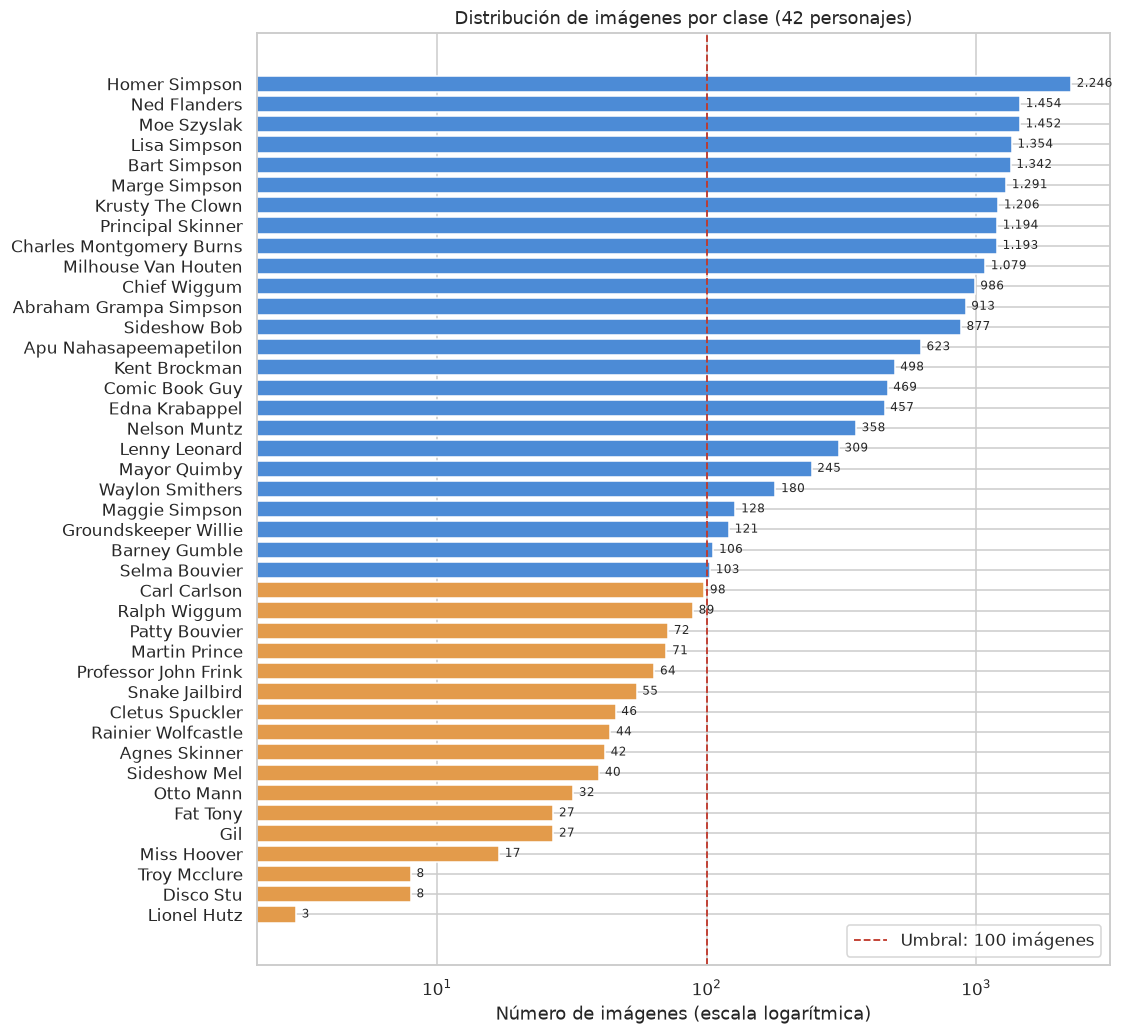

Máximo: 2.246 (homer_simpson)  |  Mínimo: 3 (lionel_hutz)
Razón de desbalance (máx/mín): 749x


In [7]:
umbral = DATOS["min_imagenes_por_clase"]
conteo = df["clase"].value_counts().sort_values()

fig, ax = plt.subplots(figsize=(10, 11))
colores = ["#4C8BD6" if n >= umbral else "#E39B4B" for n in conteo]
ax.barh([nombre_visible(c) for c in conteo.index], conteo.values, color=colores)
ax.axvline(umbral, color="#C0392B", ls="--", lw=1.2, label=f"Umbral: {umbral} imágenes")
for i, n in enumerate(conteo.values):
    ax.text(n * 1.05, i, miles(n), va="center", fontsize=8)
ax.set_xscale("log")
ax.set_xlabel("Número de imágenes (escala logarítmica)")
ax.set_title(f"Distribución de imágenes por clase ({len(conteo)} personajes)")
ax.legend(loc="lower right")
guardar_figura(fig, "01_distribucion_clases")
plt.show()

print(f"Máximo: {miles(conteo.max())} ({conteo.idxmax()})  |  Mínimo: {miles(conteo.min())} ({conteo.idxmin()})")
print(f"Razón de desbalance (máx/mín): {conteo.max() / conteo.min():.0f}x")

### 1.3 Dimensiones originales de las imágenes

Las imágenes no tienen un tamaño uniforme, por lo que es necesario estandarizar la resolución antes de entrenar (sección 3).

,count,mean,std,min,25%,50%,75%,max
ancho,20927.0,409.30,149.81,256.00,288.00,320.00,576.00,1912.00
alto,20927.0,416.88,62.22,256.00,379.00,432.00,480.00,1072.00
relacion_aspecto,20927.0,0.99,0.36,0.29,0.67,0.89,1.33,3.57


Modos de color: {'RGB': 20927}
Resoluciones más frecuentes:


,,imágenes
ancho,alto,
320,480,3004
288,432,2930
640,480,2158
576,432,1857
288,416,1715
312,352,1713
576,416,1256
624,352,892


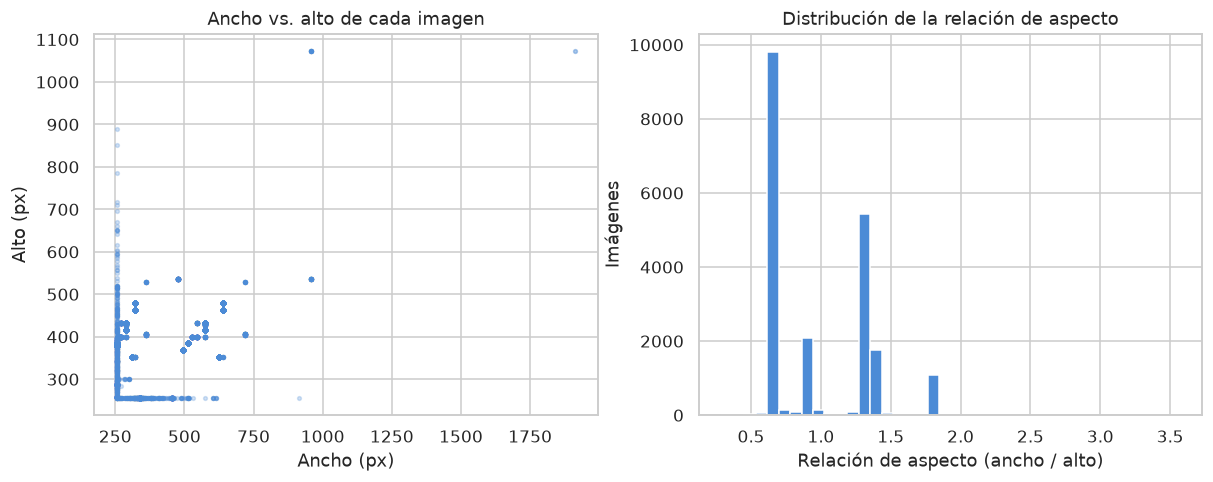

In [8]:
def leer_dimensiones(ruta):
    with Image.open(ruta) as im:
        return (*im.size, im.mode)


disponibles = df["ruta"].notna()
dimensiones = pd.DataFrame(
    [leer_dimensiones(r) for r in df.loc[disponibles, "ruta"]],
    columns=["ancho", "alto", "modo"],
    index=df.index[disponibles],
)
df = df.join(dimensiones)
df["relacion_aspecto"] = df["ancho"] / df["alto"]
if not disponibles.all():
    print(f"Se analizan {miles(disponibles.sum())} imágenes; {miles((~disponibles).sum())} de clases excluidas no están en el dataset dividido.")

display(df[["ancho", "alto", "relacion_aspecto"]].describe().round(2).T)
print("Modos de color:", df["modo"].value_counts().to_dict())
print("Resoluciones más frecuentes:")
display(df.groupby(["ancho", "alto"]).size().sort_values(ascending=False).head(8).rename("imágenes").to_frame())

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].scatter(df["ancho"], df["alto"], s=6, alpha=0.25, color="#4C8BD6")
axes[0].set(xlabel="Ancho (px)", ylabel="Alto (px)", title="Ancho vs. alto de cada imagen")
axes[1].hist(df["relacion_aspecto"].dropna(), bins=40, color="#4C8BD6")
axes[1].set(xlabel="Relación de aspecto (ancho / alto)", ylabel="Imágenes", title="Distribución de la relación de aspecto")
guardar_figura(fig, "02_dimensiones")
plt.show()

### 1.4 Ejemplos de imágenes

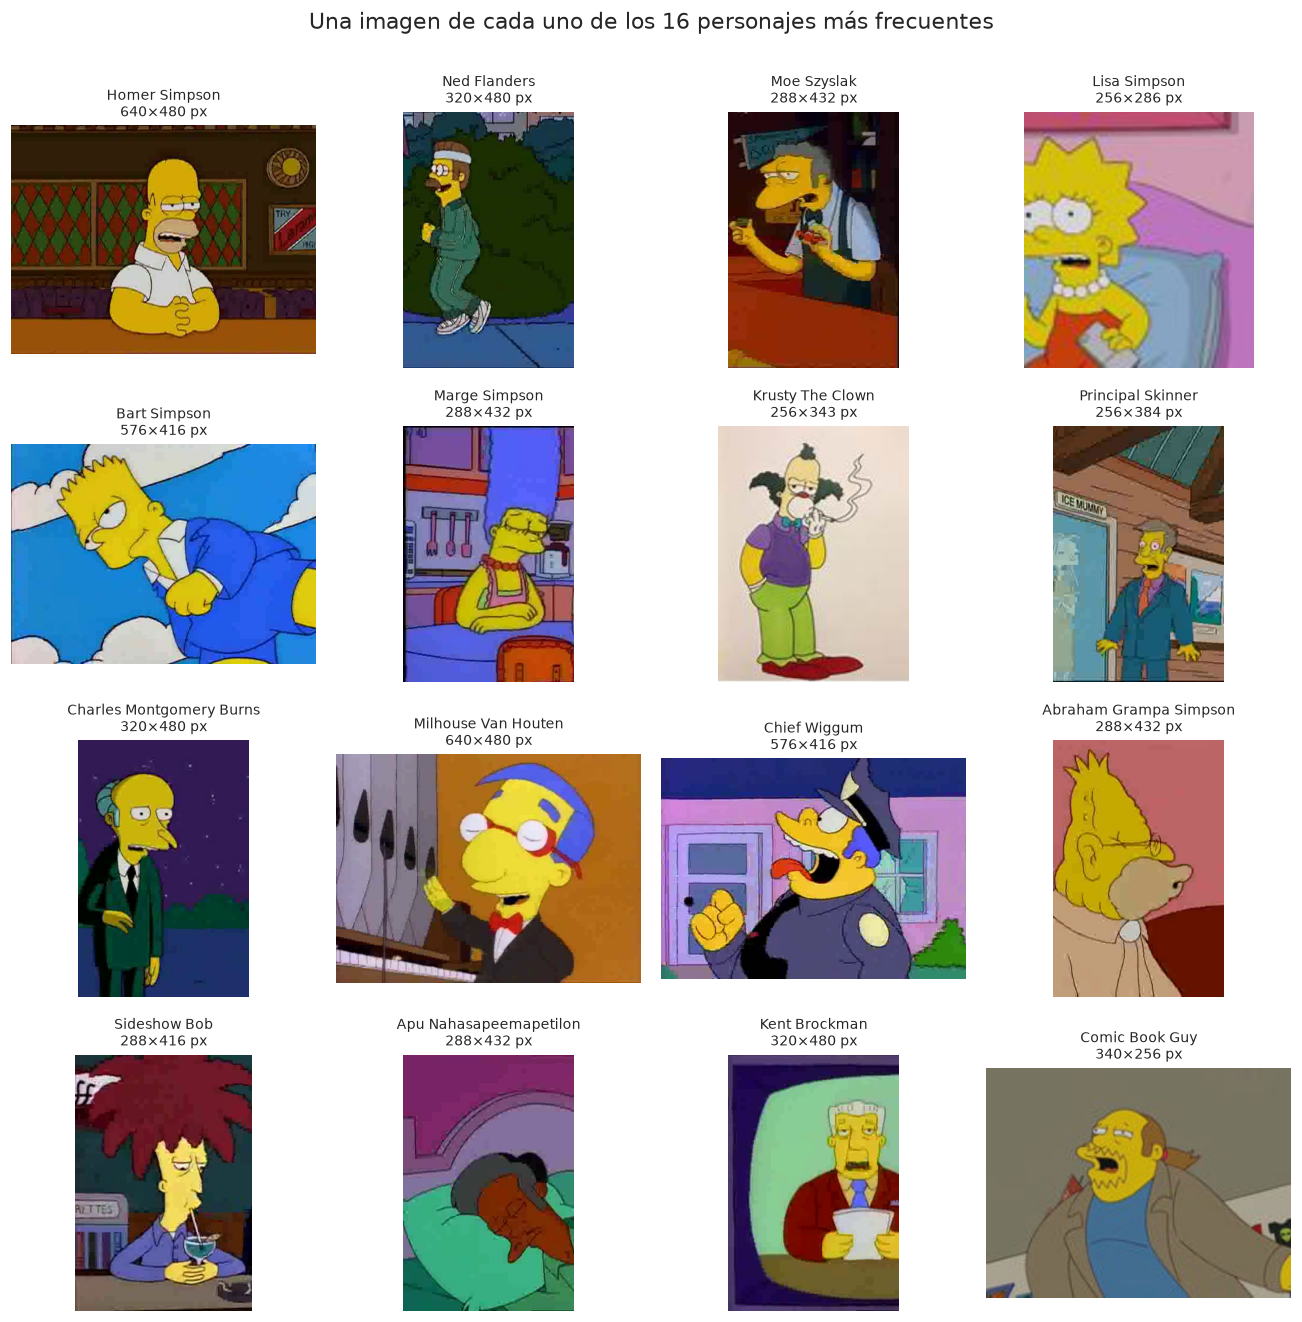

In [9]:
clases_ejemplo = conteo.sort_values(ascending=False).index[:16]
fig, axes = plt.subplots(4, 4, figsize=(12, 12))
for ax, clase in zip(axes.flat, clases_ejemplo):
    fila = df[(df["clase"] == clase) & df["ruta"].notna()].sample(1, random_state=DATOS["semilla"]).iloc[0]
    ax.imshow(Image.open(fila["ruta"]).convert("RGB"))
    ax.set_title(f"{nombre_visible(clase)}\n{int(fila['ancho'])}×{int(fila['alto'])} px", fontsize=9)
    ax.axis("off")
fig.suptitle("Una imagen de cada uno de los 16 personajes más frecuentes", y=1.0)
fig.tight_layout()
guardar_figura(fig, "03_ejemplos")
plt.show()

### 1.5 Filtro de clases

Se conservan solo los personajes con al menos `min_imagenes_por_clase` imágenes. Con menos ejemplos, la clase quedaría con muy pocas imágenes en validación y prueba (en el caso extremo, 0 o 1), lo que haría poco confiables su *precision*, su *recall* y su fila en la matriz de confusión. La justificación completa está en `informe_yolo11.md`.

In [10]:
CLASES = sorted(conteo[conteo >= umbral].index)  # orden alfabético = orden de índices en Ultralytics
excluidas = conteo[conteo < umbral].sort_values(ascending=False)
df_modelo = df[df["clase"].isin(CLASES)].reset_index(drop=True)

print(f"Clases conservadas: {len(CLASES)} ({miles(len(df_modelo))} imágenes)")
print(f"Clases excluidas:   {len(excluidas)} ({miles(excluidas.sum())} imágenes)")
display(excluidas.rename("imágenes").rename_axis("clase excluida").to_frame())

Clases conservadas: 25 (20.184 imágenes)
Clases excluidas:   17 (743 imágenes)


,imágenes
clase excluida,
carl_carlson,98
ralph_wiggum,89
patty_bouvier,72
martin_prince,71
professor_john_frink,64
snake_jailbird,55
cletus_spuckler,46
rainier_wolfcastle,44
agnes_skinner,42


## 2. División en entrenamiento, validación y prueba

- **Proporciones:** 70 % entrenamiento, 15 % validación y 15 % prueba.
- **Estratificada:** cada subconjunto mantiene la proporción de imágenes de cada personaje, lo que es clave en un dataset desbalanceado.
- **Reproducible:** semilla fija (42). La asignación de cada imagen se guarda en `division.csv` dentro de la carpeta de la prueba.
- **Validación** se usa para elegir el mejor peso y para la detención anticipada; **prueba** solo se usa al final para medir la generalización.

**Dataset dividido.** Ultralytics exige la estructura `train/`, `val/` y `test/` con una subcarpeta por clase. Esa estructura está en `dataset/simpsons_split/` (copias de las imágenes, unos 550 MB) junto con su manifiesto `division.csv`. El notebook calcula la división y:

- si coincide con la de `dataset/simpsons_split/`, **la reutiliza** sin copiar nada;
- si no existe o no coincide (por ejemplo, porque se cambió el umbral de clases), **la vuelve a crear** desde el dataset original.

In [11]:
p = DATOS["proporciones"]
semilla = DATOS["semilla"]

train_df, temp_df = train_test_split(
    df_modelo, test_size=p["val"] + p["test"], stratify=df_modelo["clase"], random_state=semilla
)
val_df, test_df = train_test_split(
    temp_df, test_size=p["test"] / (p["val"] + p["test"]), stratify=temp_df["clase"], random_state=semilla
)
division = pd.concat(
    [train_df.assign(subconjunto="train"), val_df.assign(subconjunto="val"), test_df.assign(subconjunto="test")]
).reset_index(drop=True)
division["ruta_division"] = [
    f"{s}/{c}/{Path(a).name}" for s, c, a in zip(division["subconjunto"], division["clase"], division["archivo"])
]

tabla_division = division.pivot_table(index="clase", columns="subconjunto", values="md5", aggfunc="count")
tabla_division = tabla_division[["train", "val", "test"]]
tabla_division["total"] = tabla_division.sum(axis=1)

for s in ["train", "val", "test"]:
    n = (division["subconjunto"] == s).sum()
    print(f"{s:>5}: {miles(n):>6} imágenes ({n / len(division):.1%})")
display(tabla_division.sort_values("total", ascending=False))

train: 14.128 imágenes (70.0%)
  val:  3.028 imágenes (15.0%)
 test:  3.028 imágenes (15.0%)


subconjunto,train,val,test,total
clase,,,,
homer_simpson,1572,337,337,2246
ned_flanders,1018,218,218,1454
moe_szyslak,1016,218,218,1452
lisa_simpson,948,203,203,1354
bart_simpson,939,202,201,1342
marge_simpson,904,193,194,1291
krusty_the_clown,844,181,181,1206
principal_skinner,836,179,179,1194
charles_montgomery_burns,835,179,179,1193


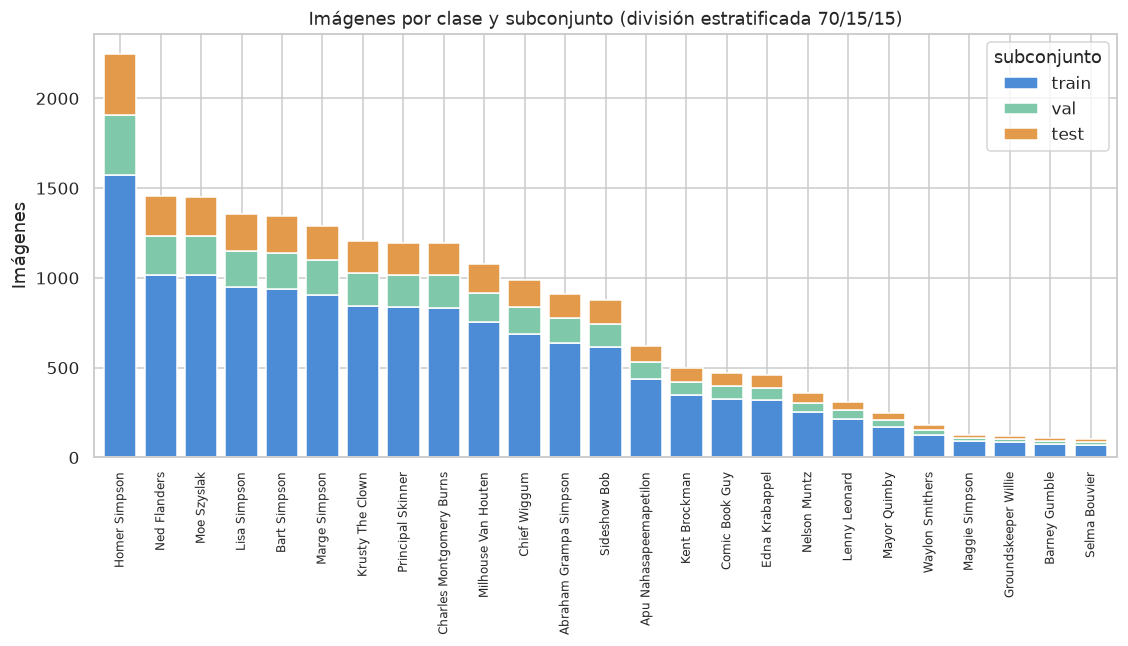

In [12]:
fig, ax = plt.subplots(figsize=(12, 5))
orden = tabla_division.sort_values("total", ascending=False)
orden[["train", "val", "test"]].rename(index=nombre_visible).plot.bar(
    stacked=True, ax=ax, color=["#4C8BD6", "#7FC8A9", "#E39B4B"], width=0.8
)
ax.set(ylabel="Imágenes", xlabel="", title="Imágenes por clase y subconjunto (división estratificada 70/15/15)")
ax.tick_params(axis="x", labelsize=8)
guardar_figura(fig, "04_division")
plt.show()

In [13]:
def construir_manifiesto(df_todas, division):
    # Todas las imágenes originales con su estado: train, val, test, excluida o duplicada
    manifiesto = df_todas[["archivo", "clase", "md5"]].merge(
        division[["archivo", "subconjunto", "ruta_division"]], on="archivo", how="left"
    )
    if DATOS["eliminar_duplicados"]:
        manifiesto.loc[df_todas.duplicated("md5", keep="first").values, "subconjunto"] = "duplicada"
    manifiesto["subconjunto"] = manifiesto["subconjunto"].fillna("excluida")
    return manifiesto


def division_vigente(division):
    # True si dataset/simpsons_split/ ya contiene exactamente esta división
    if not MANIFIESTO.exists():
        return False
    actual = pd.read_csv(MANIFIESTO)
    actual = actual[actual["subconjunto"].isin(["train", "val", "test"])].set_index("archivo")["subconjunto"]
    nueva = division.set_index("archivo")["subconjunto"]
    return actual.sort_index().equals(nueva.sort_index()) and all(
        (SPLIT_DIR / r).exists() for r in division["ruta_division"]
    )


def crear_division(division, destino):
    assert destino.name == "simpsons_split", "Ruta de división inesperada; no se borra nada."
    if destino.exists():
        shutil.rmtree(destino)  # solo contiene copias; el dataset original no se toca
    for fila in division.itertuples():
        archivo_destino = destino / fila.ruta_division
        archivo_destino.parent.mkdir(parents=True, exist_ok=True)
        shutil.copy2(fila.ruta, archivo_destino)


if division_vigente(division):
    print(f"Se reutiliza {SPLIT_DIR.relative_to(BASE_DIR)}/: coincide con la división calculada.")
elif ORIGINAL_DISPONIBLE:
    print(f"Creando {SPLIT_DIR.relative_to(BASE_DIR)}/ (copia de {miles(len(division))} imágenes)...")
    crear_division(division, SPLIT_DIR)
    construir_manifiesto(df_todas, division).to_csv(MANIFIESTO, index=False)  # se escribe al final: marca la división como completa
    print("Dataset dividido creado.")
else:
    raise RuntimeError(
        "La división calculada no coincide con dataset/simpsons_split/ y no está el dataset original para regenerarla."
    )

# Desde aquí se trabaja con las imágenes del dataset dividido
division["ruta"] = [SPLIT_DIR / r for r in division["ruta_division"]]
train_df, val_df, test_df = (division[division["subconjunto"] == s].reset_index(drop=True) for s in ["train", "val", "test"])

for s in ["train", "val", "test"]:
    carpeta = SPLIT_DIR / s
    n_img = sum(1 for p in carpeta.rglob("*") if p.suffix.lower() in EXTENSIONES)
    n_cls = sum(1 for d in carpeta.iterdir() if d.is_dir())
    print(f"{s:>5}/: {n_cls} clases, {miles(n_img)} imágenes")

Se reutiliza dataset/simpsons_split/: coincide con la división calculada.
train/: 25 clases, 14.128 imágenes
  val/: 25 clases, 3.028 imágenes
 test/: 25 clases, 3.028 imágenes


## 3. Preprocesamiento y aumentación de imágenes

**Entrenamiento** (transformaciones aleatorias en cada época, para mitigar el sobreajuste):

1. `RandomResizedCrop(224, scale=(0.5, 1.0))`: recorta una región aleatoria de entre 50 % y 100 % del área y la lleva a 224×224 px. Equivale a un **zoom** aleatorio y además **estandariza la resolución**.
2. `RandomHorizontalFlip(p=0.5)`: **giro** horizontal. No se usa giro vertical, porque los personajes nunca aparecen de cabeza.
3. `RandAugment`: aplica operaciones aleatorias como **rotación**, traslación, cizalle, brillo, contraste, nitidez, ecualización y posterización. Cuando RandAugment está activo, Ultralytics desactiva el `ColorJitter` (parámetros `hsv_*`), porque RandAugment ya altera el color.
4. `ToTensor()`: convierte a tensor y **normaliza los píxeles a [0, 1]** (divide por 255). Ultralytics usa media 0 y desviación 1, así que el rango queda en [0, 1].
5. `RandomErasing(p=0.4)`: borra un rectángulo aleatorio, lo que obliga al modelo a no depender de una sola zona de la imagen.

**Validación, prueba e inferencia** (determinista): redimensiona el lado corto a 224 px (conserva la relación de aspecto), recorta el centro a 224×224 y escala a [0, 1]. La aplicación web debe usar exactamente este mismo preprocesamiento.

In [14]:
aumentacion = classify_augmentations(
    size=IMGSZ,
    scale=(1.0 - HIPERPARAMETROS["scale"], 1.0),
    hflip=HIPERPARAMETROS["fliplr"],
    vflip=HIPERPARAMETROS["flipud"],
    erasing=HIPERPARAMETROS["erasing"],
    auto_augment=HIPERPARAMETROS["auto_augment"],
    hsv_h=HIPERPARAMETROS["hsv_h"],
    hsv_s=HIPERPARAMETROS["hsv_s"],
    hsv_v=HIPERPARAMETROS["hsv_v"],
)
transformacion_eval = classify_transforms(size=IMGSZ)
print("Entrenamiento:", aumentacion, sep="\n")
print("\nValidación / prueba / inferencia:", transformacion_eval, sep="\n")

Entrenamiento:
Compose(
    RandomResizedCrop(size=(224, 224), scale=(0.5, 1.0), ratio=(0.75, 1.3333), interpolation=bilinear, antialias=True)
    RandomHorizontalFlip(p=0.5)
    RandAugment(num_ops=2, magnitude=9, num_magnitude_bins=31, interpolation=InterpolationMode.BILINEAR, fill=None)
    ToTensor()
    Normalize(mean=tensor([0., 0., 0.]), std=tensor([1., 1., 1.]))
    RandomErasing(p=0.4, scale=(0.02, 0.33), ratio=(0.3, 3.3), value=0, inplace=True)
)

Validación / prueba / inferencia:
Compose(
    Resize(size=224, interpolation=bilinear, max_size=None, antialias=True)
    CenterCrop(size=(224, 224))
    ToTensor()
    Normalize(mean=tensor([0., 0., 0.]), std=tensor([1., 1., 1.]))
)


In [15]:
# Verificación de la estandarización y la normalización
ejemplo = train_df.iloc[0]
imagen = Image.open(ejemplo["ruta"]).convert("RGB")
tensor_eval = transformacion_eval(imagen)
tensor_aum = aumentacion(imagen)
print(f"Imagen original:         {imagen.size[0]}×{imagen.size[1]} px, modo {imagen.mode}, valores 0–255")
print(f"Tensor de evaluación:    {tuple(tensor_eval.shape)}, rango [{tensor_eval.min():.3f}, {tensor_eval.max():.3f}]")
print(f"Tensor de entrenamiento: {tuple(tensor_aum.shape)}, rango [{tensor_aum.min():.3f}, {tensor_aum.max():.3f}]")

Imagen original:         576×432 px, modo RGB, valores 0–255
Tensor de evaluación:    (3, 224, 224), rango [0.000, 0.980]
Tensor de entrenamiento: (3, 224, 224), rango [0.000, 1.000]


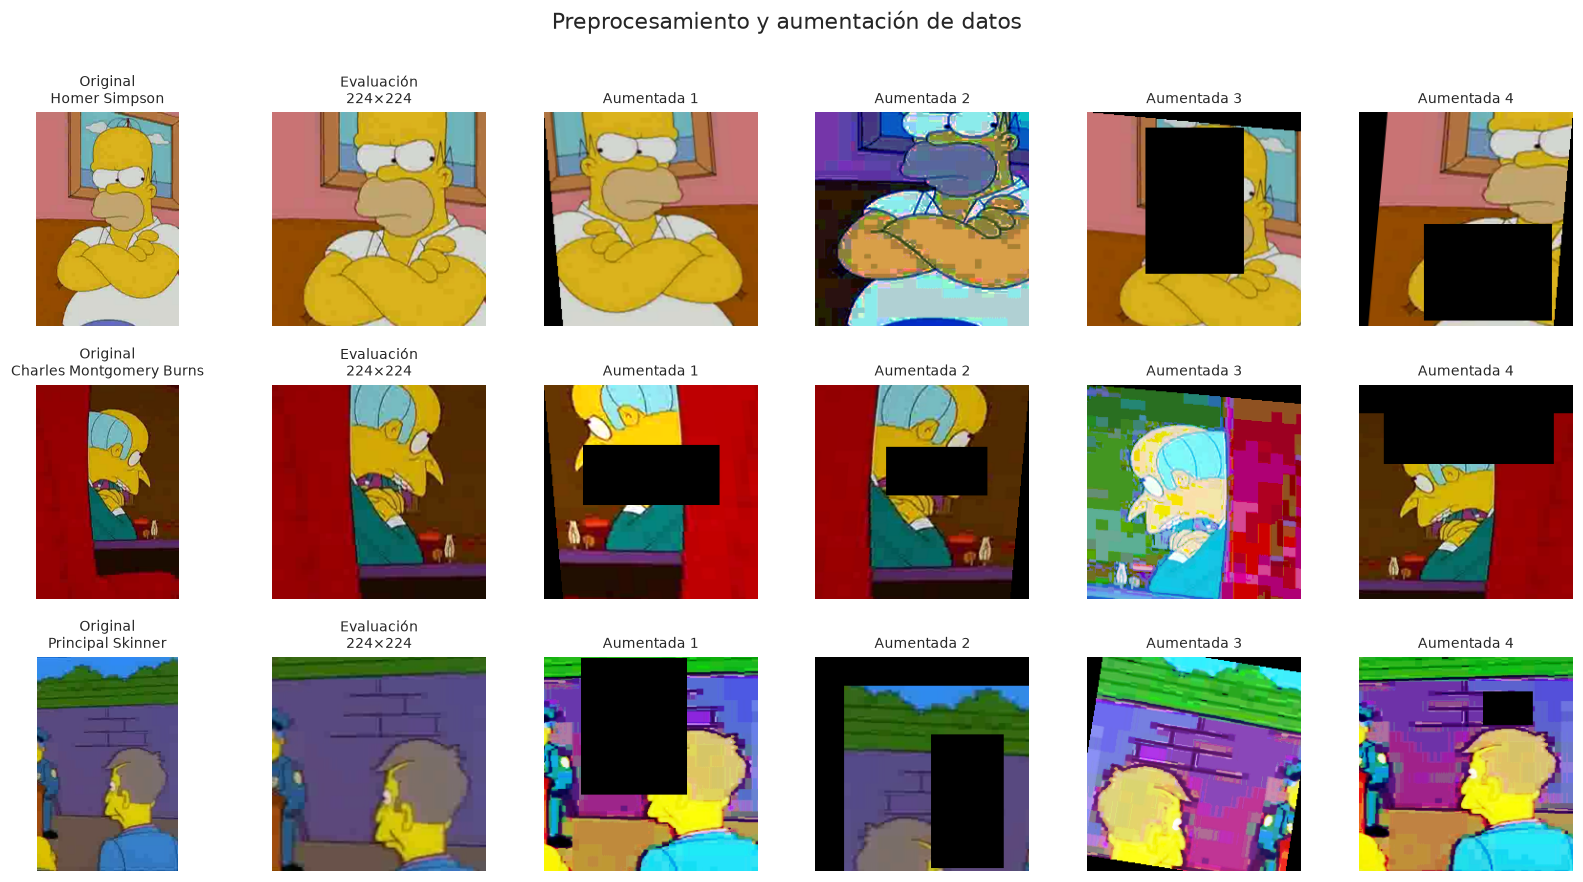

In [16]:
def a_imagen(tensor):
    return tensor.permute(1, 2, 0).clamp(0, 1).numpy()


ejemplos = train_df.sample(3, random_state=semilla)
fig, axes = plt.subplots(3, 6, figsize=(15, 8))
for fila_axes, (_, fila) in zip(axes, ejemplos.iterrows()):
    imagen = Image.open(fila["ruta"]).convert("RGB")
    fila_axes[0].imshow(imagen)
    fila_axes[0].set_title(f"Original\n{nombre_visible(fila['clase'])}", fontsize=9)
    fila_axes[1].imshow(a_imagen(transformacion_eval(imagen)))
    fila_axes[1].set_title(f"Evaluación\n{IMGSZ}×{IMGSZ}", fontsize=9)
    for j, ax in enumerate(fila_axes[2:], start=1):
        ax.imshow(a_imagen(aumentacion(imagen)))
        ax.set_title(f"Aumentada {j}", fontsize=9)
for ax in axes.flat:
    ax.axis("off")
fig.suptitle("Preprocesamiento y aumentación de datos", y=1.0)
fig.tight_layout()
guardar_figura(fig, "05_aumentacion")
plt.show()

## 4. Arquitectura: YOLO11m-cls con transfer learning

**Por qué transfer learning.** Con unas 14.000 imágenes de entrenamiento, entrenar una CNN profunda desde cero tiende al sobreajuste. Un modelo preentrenado en ImageNet (1,28 millones de imágenes, 1.000 clases) ya aprendió filtros útiles: bordes y colores en las primeras capas, texturas y formas en las intermedias, y partes de objetos en las profundas. Se hace **fine-tuning de todas las capas**: los pesos de ImageNet son el punto de partida y se ajustan a los personajes.

**Estructura de YOLO11m-cls**

| Bloque | Función |
|---|---|
| `Conv` (kernel 3×3, *stride* 2) | Extraen características y reducen la resolución a la mitad en cada etapa (*stride* total 32: de 224×224 a 7×7). Cada `Conv` incluye *batch normalization* y activación SiLU. |
| `C3k2` | Bloques CSP (*Cross Stage Partial*): dividen los canales, pasan una parte por *bottlenecks* con kernels 3×3 y luego concatenan. Mejoran el flujo del gradiente con menos parámetros que una convolución equivalente. |
| `C2PSA` | Bloque de **atención espacial** (*Position-Sensitive Attention*): relaciona regiones lejanas de la imagen, por ejemplo el pelo y la ropa de un personaje. |
| `Classify` (cabeza) | Convolución 1×1 a 1.280 canales → *global average pooling* (un valor por canal, invariante a la posición y con menos parámetros que aplanar) → *dropout* → capa lineal a 25 clases → *softmax* en inferencia. |

**Por qué la variante *medium*.** Ofrece un punto intermedio en la familia YOLO11-cls: bastante más capacidad que las variantes *nano* y *small*, y bastante menos costo que *large* y *x-large*. Esto importa porque varios personajes comparten rasgos (piel amarilla, mismo estilo de dibujo), pero el modelo debe seguir siendo liviano para desplegarse en una aplicación web y entrenarse en una GPU de 4 a 8 GB.

**Decisiones de entrenamiento**

- **Función de pérdida:** entropía cruzada (*cross-entropy*), estándar en clasificación multiclase de etiqueta única.
- **AdamW con `lr0 = 5e-4`:** una tasa moderada para no destruir los pesos preentrenados. El *weight decay* desacoplado regulariza.
- **Calentamiento de 3 épocas y decaimiento coseno:** la cabeza nueva parte con pesos aleatorios. El calentamiento evita gradientes grandes al inicio, y el coseno reduce la tasa de aprendizaje suavemente hasta `lr0 · lrf`.
- **Dropout 0,2, aumentación de datos y detención anticipada (paciencia 10):** tres mecanismos contra el sobreajuste.
- **Precisión mixta (AMP) y AutoBatch:** menos memoria y más velocidad, y el tamaño de lote se ajusta solo a la GPU disponible.
- **224×224 px:** es la resolución de preentrenamiento y está cerca del tamaño de las imágenes originales, así que no se pierde detalle relevante.

In [17]:
modelo_base = YOLO(MODELO_BASE)
capas, n_parametros, _, gflops = modelo_base.model.info(verbose=True, imgsz=IMGSZ)
print(f"{MODELO_BASE}: {capas} capas, {n_parametros / 1e6:.2f} M parámetros, {gflops:.2f} GFLOPs a {IMGSZ}×{IMGSZ}")
print("\nCabeza original (1.000 clases de ImageNet; Ultralytics la reemplaza por una de", len(CLASES), "clases al entrenar):")
print(modelo_base.model.model[-1])

YOLO11m-cls summary: 106 layers, 11,634,216 parameters, 0 gradients, 4.9 GFLOPs
yolo11m-cls.pt: 106 capas, 11.63 M parámetros, 4.86 GFLOPs a 224×224

Cabeza original (1.000 clases de ImageNet; Ultralytics la reemplaza por una de 25 clases al entrenar):
Classify(
  (conv): Conv(
    (conv): Conv2d(512, 1280, kernel_size=(1, 1), stride=(1, 1), bias=False)
    (bn): BatchNorm2d(1280, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (act): SiLU(inplace=True)
  )
  (pool): AdaptiveAvgPool2d(output_size=1)
  (drop): Dropout(p=0.0, inplace=True)
  (linear): Linear(in_features=1280, out_features=1000, bias=True)
)


In [18]:
# Resumen de las capas (tipo de bloque y número de parámetros)
resumen_capas = pd.DataFrame(
    [
        {"índice": i, "bloque": type(m).__name__, "parámetros": sum(p.numel() for p in m.parameters())}
        for i, m in enumerate(modelo_base.model.model)
    ]
)
display(resumen_capas)

,índice,bloque,parámetros
0,0,Conv,1856
1,1,Conv,73984
2,2,C3k2,111872
3,3,Conv,590336
4,4,C3k2,444928
5,5,Conv,2360320
6,6,C3k2,1380352
7,7,Conv,2360320
8,8,C3k2,1380352
9,9,C2PSA,990976


## 5. Entrenamiento

Antes de entrenar se guardan en la carpeta de la prueba: la configuración completa, la división, el orden de clases y una copia del notebook. El registro del entrenamiento se escribe en `entrenamiento.log`.

**Loss y accuracy de entrenamiento.** Ultralytics registra por época la *loss* de entrenamiento (calculada con aumentación) y la *loss*/*accuracy* de validación, pero no la *accuracy* de entrenamiento. Para comparar entrenamiento contra validación en igualdad de condiciones, un *callback* evalúa al final de cada época una muestra fija y estratificada de imágenes de *train*, **sin aumentación**, con el mismo modelo EMA (*Exponential Moving Average*) que usa la validación.

**Mejor peso.** Ultralytics guarda como `best.pt` la época con mejor *fitness* de validación, que en clasificación es el promedio de la *accuracy* top-1 y top-5.

In [19]:
class MetricasEntrenamiento:
    # Mide loss y accuracy sobre una muestra fija de train (sin aumentación) al final de cada época

    def __init__(self, rutas, etiquetas, imgsz, lote=32):
        transformacion = classify_transforms(size=imgsz)
        imagenes = [transformacion(Image.open(r).convert("RGB")) for r in rutas]
        self.x = (torch.stack(imagenes) * 255).round().to(torch.uint8)  # uint8 para ahorrar memoria
        self.y = torch.tensor(etiquetas)
        self.lote = lote
        self.historial = {}

    @torch.no_grad()
    def __call__(self, trainer):
        modelo = trainer.ema.ema if trainer.ema else trainer.model
        estaba_entrenando = modelo.training
        modelo.eval()
        parametro = next(modelo.parameters())
        perdida, aciertos = 0.0, 0
        for i in range(0, len(self.y), self.lote):
            x = self.x[i : i + self.lote].to(parametro.device, parametro.dtype) / 255
            y = self.y[i : i + self.lote].to(parametro.device)
            with torch.autocast(device_type=parametro.device.type, enabled=parametro.device.type == "cuda"):
                salida = modelo(x)
            logits = salida[1] if isinstance(salida, (tuple, list)) else salida
            perdida += F.cross_entropy(logits.float(), y, reduction="sum").item()
            aciertos += (logits.argmax(1) == y).sum().item()
        modelo.train(estaba_entrenando)
        n = len(self.y)
        self.historial[trainer.epoch + 1] = {
            "train/loss_sin_aumentacion": perdida / n,
            "train/accuracy_top1": aciertos / n,
        }


def ruta_notebook():
    ruta = globals().get("__vsc_ipynb_file__")  # VS Code define esta variable con la ruta del notebook
    return Path(ruta) if ruta else BASE_DIR / "yolo11.ipynb"

In [20]:
if TEST_A_EVALUAR is None:
    # 1) Registro previo al entrenamiento
    division_csv = division.assign(ruta=division["ruta"].map(lambda r: r.relative_to(BASE_DIR).as_posix()))
    division_csv[["ruta", "archivo", "clase", "subconjunto", "md5"]].to_csv(TEST_DIR / "division.csv", index=False)
    guardar_json(CLASES, TEST_DIR / "clases.json")
    if ruta_notebook().exists():
        shutil.copy2(ruta_notebook(), TEST_DIR / "yolo11_copia.ipynb")

    configuracion = {
        "prueba": NOMBRE_TEST,
        "modelo_base": MODELO_BASE,
        "datos": {
            **DATOS,
            "dataset_dividido": SPLIT_DIR.relative_to(BASE_DIR).as_posix(),
            "clases": len(CLASES),
            "imagenes": division["subconjunto"].value_counts().to_dict(),
            "clases_excluidas": excluidas.to_dict(),
        },
        "hiperparametros": HIPERPARAMETROS,
        "evaluacion": EVALUACION,
        "entorno": ENTORNO,
        "inicio": datetime.now().isoformat(timespec="seconds"),
    }
    guardar_json(configuracion, TEST_DIR / "configuracion.json")

    # 2) Muestra fija y estratificada de train para medir accuracy de entrenamiento
    n_muestra = min(EVALUACION["muestra_train_por_epoca"], len(train_df) - len(CLASES))
    muestra, _ = train_test_split(train_df, train_size=n_muestra, stratify=train_df["clase"], random_state=semilla)
    metricas_train = MetricasEntrenamiento(
        muestra["ruta"].tolist(), [CLASES.index(c) for c in muestra["clase"]], IMGSZ
    )

    # 3) Entrenamiento
    modelo = YOLO(MODELO_BASE)
    modelo.add_callback("on_train_epoch_end", metricas_train)
    registro = logging.FileHandler(TEST_DIR / "entrenamiento.log", encoding="utf-8")
    registro.setFormatter(logging.Formatter("%(asctime)s %(message)s"))
    ULTRALYTICS_LOGGER.addHandler(registro)
    inicio = time.time()
    try:
        modelo.train(
            data=str(SPLIT_DIR),
            project=str(RESULTADOS_DIR),
            name=NOMBRE_TEST,
            exist_ok=True,
            device=DEVICE,
            plots=True,
            **HIPERPARAMETROS,
        )
    finally:
        ULTRALYTICS_LOGGER.removeHandler(registro)
        registro.close()
    duracion_min = (time.time() - inicio) / 60

    # 4) Historial por época: métricas de Ultralytics + métricas de entrenamiento sin aumentación
    resultados = pd.read_csv(TEST_DIR / "results.csv")
    resultados.columns = resultados.columns.str.strip()
    extra = pd.DataFrame.from_dict(metricas_train.historial, orient="index").rename_axis("epoch").reset_index()
    historial = resultados.merge(extra, on="epoch", how="left")
    historial.to_csv(TEST_DIR / "historial.csv", index=False)

    mejor_fila = historial.loc[historial["metrics/accuracy_top1"].idxmax()]
    configuracion.update(
        {
            "fin": datetime.now().isoformat(timespec="seconds"),
            "duracion_min": round(duracion_min, 1),
            "epocas_ejecutadas": int(historial["epoch"].max()),
            "mejor_epoca_val_top1": int(mejor_fila["epoch"]),
        }
    )
    guardar_json(configuracion, TEST_DIR / "configuracion.json")
    print(f"Entrenamiento terminado en {duracion_min:.1f} min ({configuracion['epocas_ejecutadas']} épocas).")
else:
    historial = pd.read_csv(TEST_DIR / "historial.csv")
    configuracion = json.loads((TEST_DIR / "configuracion.json").read_text(encoding="utf-8"))
    print(f"Se reevalúa {NOMBRE_TEST} (entrenada el {configuracion['inicio']}); no se entrena de nuevo.")

display(historial.tail())

Ultralytics 8.4.177 🚀 Python-3.14.4 torch-2.14.1+cu130 CUDA:0 (NVIDIA GeForce RTX 4060 Laptop GPU, 7806MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=-1, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/home/felipe/Escritorio/6° semestre/deeplearning/ev2/DeepLearningModelos/dataset/simpsons_split, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.2, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.4, hsv_v=0.4, imgsz=224, iou=0.7, kobj=1.0, line_width=None, lr0=0.0005, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11m-cls.pt, momentum=0.937,

,epoch,time,train/loss,metrics/accuracy_top1,metrics/accuracy_top5,val/loss,lr/pg0,lr/pg1,lr/pg2,train/loss_sin_aumentacion,train/accuracy_top1
42,43,1093.22,0.03283,0.98976,0.99670,0.06506,0.000036,0.000036,0.000036,0.000994,0.999333
43,44,1117.80,0.03793,0.98943,0.99703,0.06313,0.000029,0.000029,0.000029,0.001214,0.999333
44,45,1142.39,0.03616,0.98910,0.99670,0.06323,0.000022,0.000022,0.000022,0.001313,0.999333
45,46,1166.95,0.02974,0.98877,0.99637,0.06257,0.000017,0.000017,0.000017,0.000962,0.999333
46,47,1191.56,0.03168,0.98910,0.99703,0.06525,0.000013,0.000013,0.000013,0.001105,0.999333


## 6. Curvas de aprendizaje

- **Loss:** la de entrenamiento con aumentación (la que optimiza el modelo), la de entrenamiento sin aumentación (muestra fija) y la de validación.
- **Accuracy:** entrenamiento (muestra fija, sin aumentación) contra validación (top-1 y top-5).

Una brecha creciente entre entrenamiento y validación indica **sobreajuste**; valores bajos en ambas indican **subajuste**.

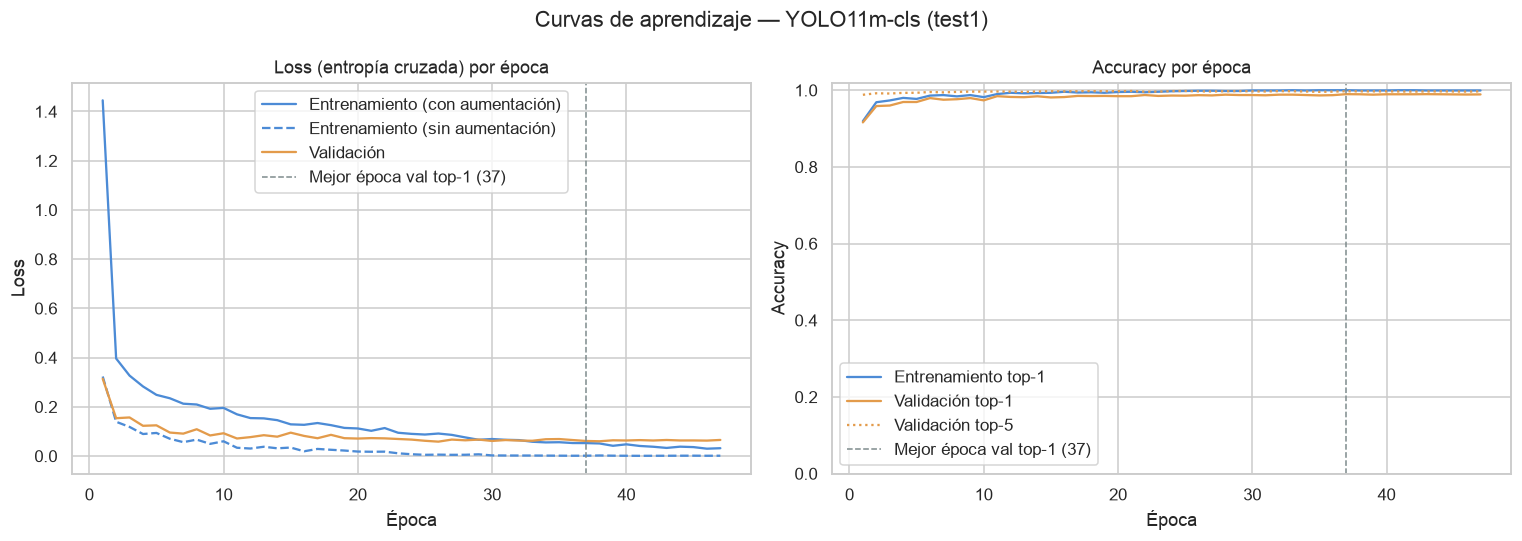

Última época: accuracy train 0.999 | val 0.989 | brecha +0.010


In [21]:
mejor_epoca = int(historial.loc[historial["metrics/accuracy_top1"].idxmax(), "epoch"])

fig, (ax_loss, ax_acc) = plt.subplots(1, 2, figsize=(14, 5))
ax_loss.plot(historial["epoch"], historial["train/loss"], label="Entrenamiento (con aumentación)", color="#4C8BD6")
if "train/loss_sin_aumentacion" in historial:
    ax_loss.plot(historial["epoch"], historial["train/loss_sin_aumentacion"], label="Entrenamiento (sin aumentación)", color="#4C8BD6", ls="--")
ax_loss.plot(historial["epoch"], historial["val/loss"], label="Validación", color="#E39B4B")
ax_loss.set(title="Loss (entropía cruzada) por época", xlabel="Época", ylabel="Loss")

if "train/accuracy_top1" in historial:
    ax_acc.plot(historial["epoch"], historial["train/accuracy_top1"], label="Entrenamiento top-1", color="#4C8BD6")
ax_acc.plot(historial["epoch"], historial["metrics/accuracy_top1"], label="Validación top-1", color="#E39B4B")
ax_acc.plot(historial["epoch"], historial["metrics/accuracy_top5"], label="Validación top-5", color="#E39B4B", ls=":")
ax_acc.set(title="Accuracy por época", xlabel="Época", ylabel="Accuracy", ylim=(0, 1.02))

for ax in (ax_loss, ax_acc):
    ax.axvline(mejor_epoca, color="#7F8C8D", ls="--", lw=1, label=f"Mejor época val top-1 ({mejor_epoca})")
    ax.legend()
fig.suptitle(f"Curvas de aprendizaje — YOLO11m-cls ({NOMBRE_TEST})")
fig.tight_layout()
guardar_figura(fig, "06_curvas_aprendizaje")
plt.show()

final = historial.iloc[-1]
if "train/accuracy_top1" in historial:
    brecha = final["train/accuracy_top1"] - final["metrics/accuracy_top1"]
    print(f"Última época: accuracy train {final['train/accuracy_top1']:.3f} | val {final['metrics/accuracy_top1']:.3f} | brecha {brecha:+.3f}")

## 7. Evaluación en el conjunto de prueba

Se evalúa el mejor peso (`best.pt`) sobre el conjunto de prueba, que el modelo no vio durante el entrenamiento ni se usó para elegir el peso. La división se lee desde `division.csv` de la prueba, así que la evaluación es la misma aunque se reevalúe después.

- **Accuracy:** proporción de imágenes bien clasificadas.
- **Precision:** de las veces que el modelo predijo un personaje, cuántas acertó.
- **Recall (sensibilidad):** de las imágenes de un personaje, cuántas reconoció.
- **F1-score:** media armónica de *precision* y *recall*.
- Promedio **macro** (todas las clases pesan igual, sensible a las clases pequeñas) y **ponderado** (según el número de imágenes de cada clase).

In [22]:
mejor_modelo = YOLO(TEST_DIR / "weights" / "best.pt")
NOMBRES = [mejor_modelo.names[i] for i in range(len(mejor_modelo.names))]
division_prueba = pd.read_csv(TEST_DIR / "division.csv")
test_eval = division_prueba[division_prueba["subconjunto"] == "test"].reset_index(drop=True)
rutas_test = [str(BASE_DIR / r) for r in test_eval["ruta"]]

lote = EVALUACION["lote_inferencia"]
probabilidades = []
for i in range(0, len(rutas_test), lote):
    for resultado in mejor_modelo.predict(rutas_test[i : i + lote], imgsz=IMGSZ, device=DEVICE, batch=lote, verbose=False):
        probabilidades.append(resultado.probs.data.float().cpu().numpy())
P = np.stack(probabilidades)

y_true = np.array([NOMBRES.index(c) for c in test_eval["clase"]])
y_pred = P.argmax(1)
confianza = P.max(1)
top5 = np.argsort(-P, axis=1)[:, :5]

prec_m, rec_m, f1_m, _ = precision_recall_fscore_support(y_true, y_pred, average="macro", zero_division=0)
prec_w, rec_w, f1_w, _ = precision_recall_fscore_support(y_true, y_pred, average="weighted", zero_division=0)
metricas_test = {
    "imagenes_test": int(len(y_true)),
    "accuracy": accuracy_score(y_true, y_pred),
    "accuracy_top5": float(np.mean([y in t for y, t in zip(y_true, top5)])),
    "precision_macro": prec_m,
    "recall_macro": rec_m,
    "f1_macro": f1_m,
    "precision_ponderada": prec_w,
    "recall_ponderado": rec_w,
    "f1_ponderado": f1_w,
}
metricas_test = {k: v if isinstance(v, int) else round(float(v), 4) for k, v in metricas_test.items()}
guardar_json(metricas_test, TEST_DIR / "metricas_test.json")
pd.Series(metricas_test, name=NOMBRE_TEST).to_frame()

,test1
imagenes_test,3028.0000
accuracy,0.9921
accuracy_top5,0.9974
precision_macro,0.9933
recall_macro,0.9883
f1_macro,0.9907
precision_ponderada,0.9921
recall_ponderado,0.9921
f1_ponderado,0.9921


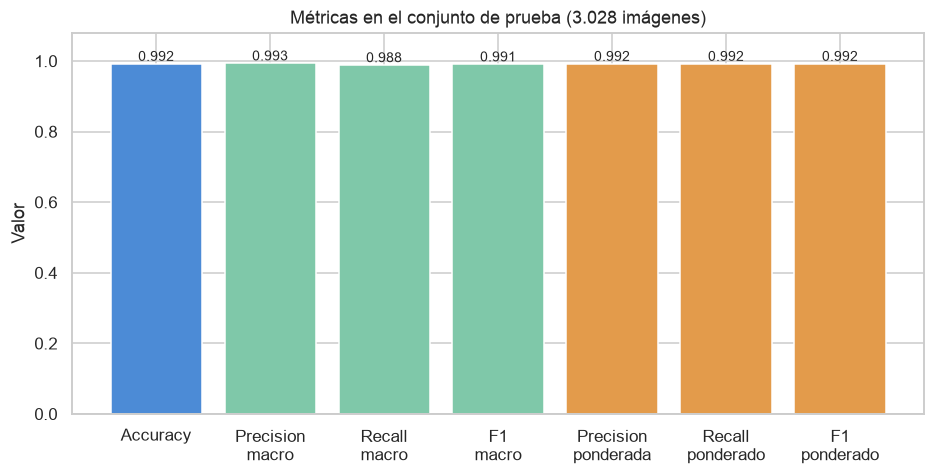

In [23]:
fig, ax = plt.subplots(figsize=(10, 4.5))
claves = ["accuracy", "precision_macro", "recall_macro", "f1_macro", "precision_ponderada", "recall_ponderado", "f1_ponderado"]
etiquetas = ["Accuracy", "Precision\nmacro", "Recall\nmacro", "F1\nmacro", "Precision\nponderada", "Recall\nponderado", "F1\nponderado"]
barras = ax.bar(etiquetas, [metricas_test[k] for k in claves], color=["#4C8BD6"] + ["#7FC8A9"] * 3 + ["#E39B4B"] * 3)
ax.bar_label(barras, fmt="%.3f", fontsize=9)
ax.set(ylim=(0, 1.08), ylabel="Valor", title=f"Métricas en el conjunto de prueba ({miles(metricas_test['imagenes_test'])} imágenes)")
guardar_figura(fig, "07_metricas_test")
plt.show()

### 7.1 Reporte por clase y matriz de confusión

In [24]:
reporte = pd.DataFrame(
    classification_report(
        y_true, y_pred, labels=range(len(NOMBRES)), target_names=NOMBRES, output_dict=True, zero_division=0
    )
).T
reporte.to_csv(TEST_DIR / "reporte_clasificacion.csv")
display(reporte.round(3))

,precision,recall,f1-score,support
abraham_grampa_simpson,1.000,1.000,1.000,137.000
apu_nahasapeemapetilon,0.979,1.000,0.989,93.000
barney_gumble,1.000,1.000,1.000,16.000
bart_simpson,0.995,0.985,0.990,201.000
charles_montgomery_burns,1.000,0.989,0.994,179.000
chief_wiggum,0.987,1.000,0.993,148.000
comic_book_guy,0.986,0.972,0.979,71.000
edna_krabappel,0.985,0.971,0.978,69.000
groundskeeper_willie,1.000,0.944,0.971,18.000
homer_simpson,0.985,0.997,0.991,337.000


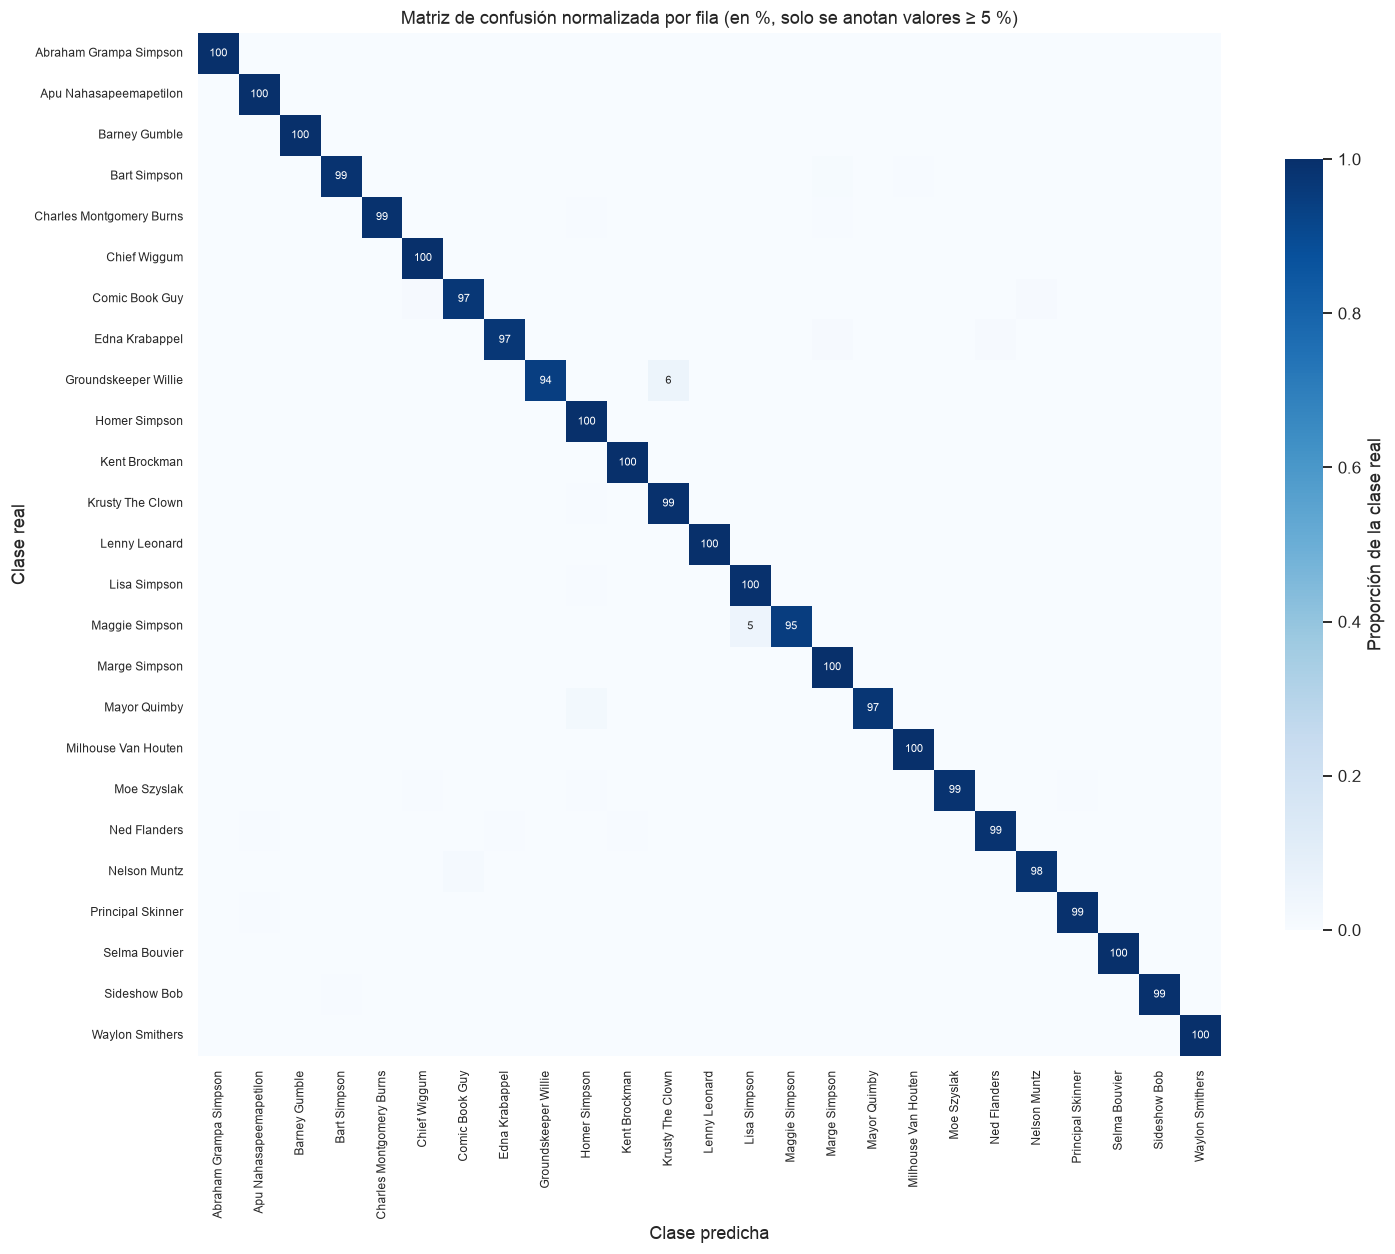

In [25]:
matriz = confusion_matrix(y_true, y_pred, labels=range(len(NOMBRES)))
pd.DataFrame(matriz, index=NOMBRES, columns=NOMBRES).to_csv(TEST_DIR / "matriz_confusion_test.csv")
matriz_norm = matriz / matriz.sum(axis=1, keepdims=True)

anotaciones = np.where(matriz_norm >= 0.05, np.vectorize(lambda v: f"{v:.0%}".replace("%", ""))(matriz_norm), "")
etiquetas_visibles = [nombre_visible(n) for n in NOMBRES]
fig, ax = plt.subplots(figsize=(15, 13))
sns.heatmap(
    matriz_norm, annot=anotaciones, fmt="", cmap="Blues", vmin=0, vmax=1, square=True,
    xticklabels=etiquetas_visibles, yticklabels=etiquetas_visibles, annot_kws={"fontsize": 7},
    cbar_kws={"label": "Proporción de la clase real", "shrink": 0.7}, ax=ax,
)
ax.set(xlabel="Clase predicha", ylabel="Clase real",
       title="Matriz de confusión normalizada por fila (en %, solo se anotan valores ≥ 5 %)")
ax.tick_params(labelsize=8)
guardar_figura(fig, "08_matriz_confusion")
plt.show()

### 7.2 Análisis de errores y sesgos

Se analiza si el desempeño depende del número de imágenes de entrenamiento de cada clase (sesgo hacia las clases mayoritarias), qué pares de personajes se confunden más y qué tan confiadas son las predicciones correctas e incorrectas. Esto último sirve para calibrar el umbral de confianza de la aplicación web.

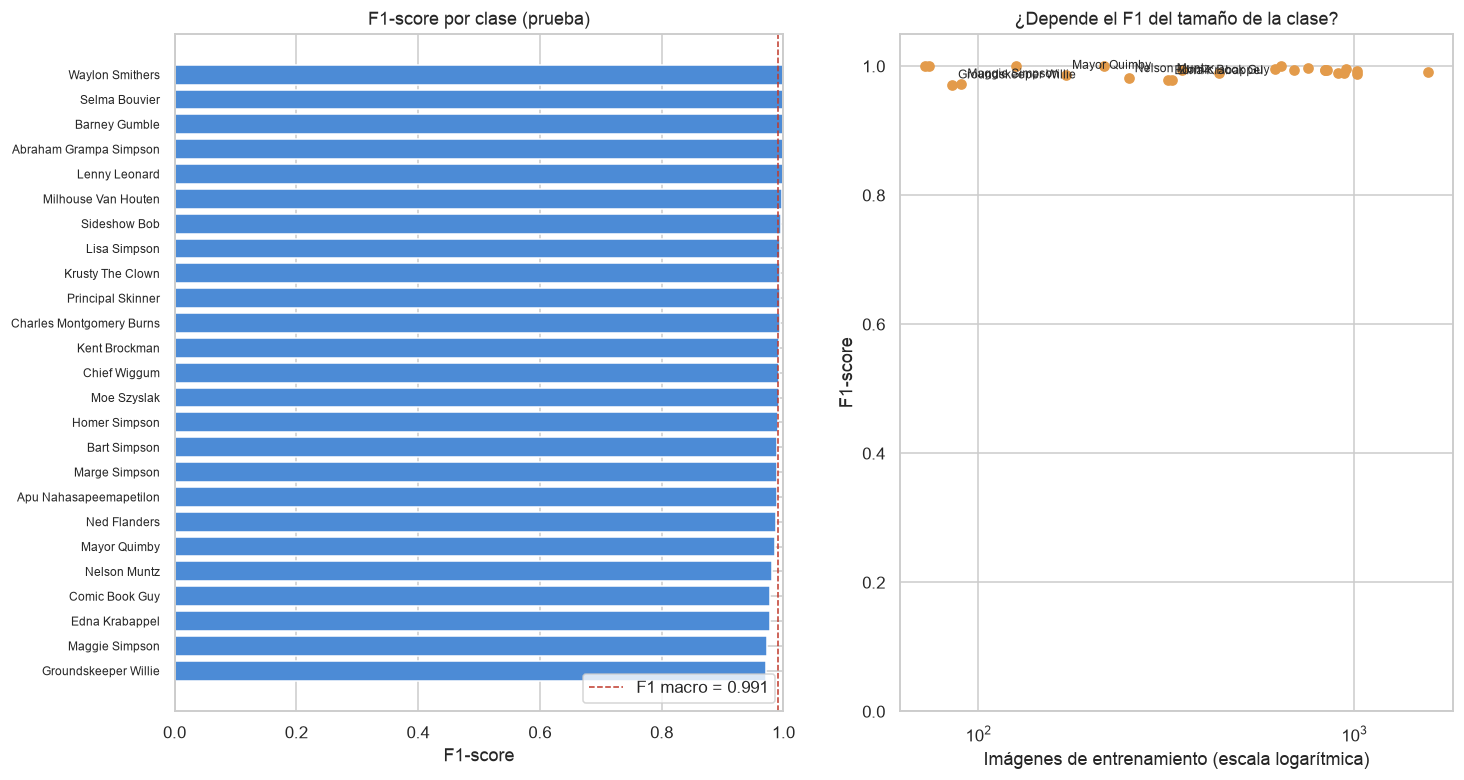

Correlación entre log(imágenes de train) y F1: +0.23


In [26]:
n_train = division_prueba[division_prueba["subconjunto"] == "train"]["clase"].value_counts()
por_clase = reporte.loc[NOMBRES, ["precision", "recall", "f1-score", "support"]].copy()
por_clase["imagenes_train"] = n_train.reindex(NOMBRES).values
por_clase = por_clase.sort_values("f1-score")

fig, (ax_bar, ax_disp) = plt.subplots(1, 2, figsize=(15, 8), gridspec_kw={"width_ratios": [1.1, 1]})
ax_bar.barh([nombre_visible(n) for n in por_clase.index], por_clase["f1-score"], color="#4C8BD6")
ax_bar.axvline(metricas_test["f1_macro"], color="#C0392B", ls="--", lw=1, label=f"F1 macro = {metricas_test['f1_macro']:.3f}")
ax_bar.set(xlim=(0, 1), xlabel="F1-score", title="F1-score por clase (prueba)")
ax_bar.tick_params(axis="y", labelsize=8)
ax_bar.legend(loc="lower right")

ax_disp.scatter(por_clase["imagenes_train"], por_clase["f1-score"], color="#E39B4B")
for nombre, fila in por_clase.head(6).iterrows():
    ax_disp.annotate(nombre_visible(nombre), (fila["imagenes_train"], fila["f1-score"]), fontsize=8, xytext=(4, 4), textcoords="offset points")
ax_disp.set_xscale("log")
ax_disp.set(xlabel="Imágenes de entrenamiento (escala logarítmica)", ylabel="F1-score", ylim=(0, 1.05),
            title="¿Depende el F1 del tamaño de la clase?")
guardar_figura(fig, "09_f1_por_clase")
plt.show()

correlacion = np.corrcoef(np.log(por_clase["imagenes_train"]), por_clase["f1-score"])[0, 1]
print(f"Correlación entre log(imágenes de train) y F1: {correlacion:+.2f}")

In [27]:
pares = [
    {"real": NOMBRES[i], "predicha": NOMBRES[j], "errores": int(matriz[i, j]), "porcentaje_de_la_clase": matriz_norm[i, j]}
    for i in range(len(NOMBRES))
    for j in range(len(NOMBRES))
    if i != j and matriz[i, j] > 0
]
confusiones = pd.DataFrame(pares).sort_values("errores", ascending=False).reset_index(drop=True)
confusiones.to_csv(TEST_DIR / "confusiones_frecuentes.csv", index=False)
print(f"Errores totales: {int((y_true != y_pred).sum())} de {len(y_true)}")
display(confusiones.head(10).style.format({"porcentaje_de_la_clase": "{:.1%}"}))

Errores totales: 24 de 3028


,real,predicha,errores,porcentaje_de_la_clase
0,bart_simpson,marge_simpson,2,1.0%
1,bart_simpson,milhouse_van_houten,1,0.5%
2,charles_montgomery_burns,homer_simpson,1,0.6%
3,charles_montgomery_burns,marge_simpson,1,0.6%
4,comic_book_guy,chief_wiggum,1,1.4%
5,comic_book_guy,nelson_muntz,1,1.4%
6,edna_krabappel,marge_simpson,1,1.4%
7,edna_krabappel,ned_flanders,1,1.4%
8,groundskeeper_willie,krusty_the_clown,1,5.6%
9,homer_simpson,ned_flanders,1,0.3%


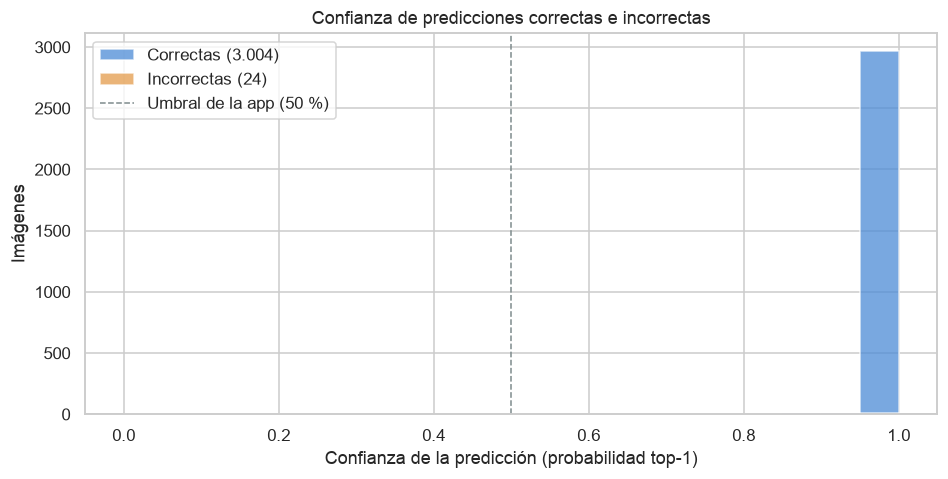

Confianza ≥ 50%: cubre 99.7% de las imágenes con accuracy 0.994
Confianza ≥ 70%: cubre 99.3% de las imágenes con accuracy 0.996
Confianza ≥ 90%: cubre 98.7% de las imágenes con accuracy 0.997


In [28]:
acierto = y_true == y_pred
fig, ax = plt.subplots(figsize=(10, 4.5))
bins = np.linspace(0, 1, 21)
ax.hist(confianza[acierto], bins=bins, alpha=0.75, label=f"Correctas ({miles(acierto.sum())})", color="#4C8BD6")
ax.hist(confianza[~acierto], bins=bins, alpha=0.75, label=f"Incorrectas ({miles((~acierto).sum())})", color="#E39B4B")
ax.axvline(0.5, color="#7F8C8D", ls="--", lw=1, label="Umbral de la app (50 %)")
ax.set(xlabel="Confianza de la predicción (probabilidad top-1)", ylabel="Imágenes", title="Confianza de predicciones correctas e incorrectas")
ax.legend()
guardar_figura(fig, "10_confianza")
plt.show()

for u in (0.5, 0.7, 0.9):
    sobre = confianza >= u
    if sobre.any():
        print(f"Confianza ≥ {u:.0%}: cubre {sobre.mean():.1%} de las imágenes con accuracy {acierto[sobre].mean():.3f}")
    else:
        print(f"Confianza ≥ {u:.0%}: ninguna predicción alcanza este nivel")

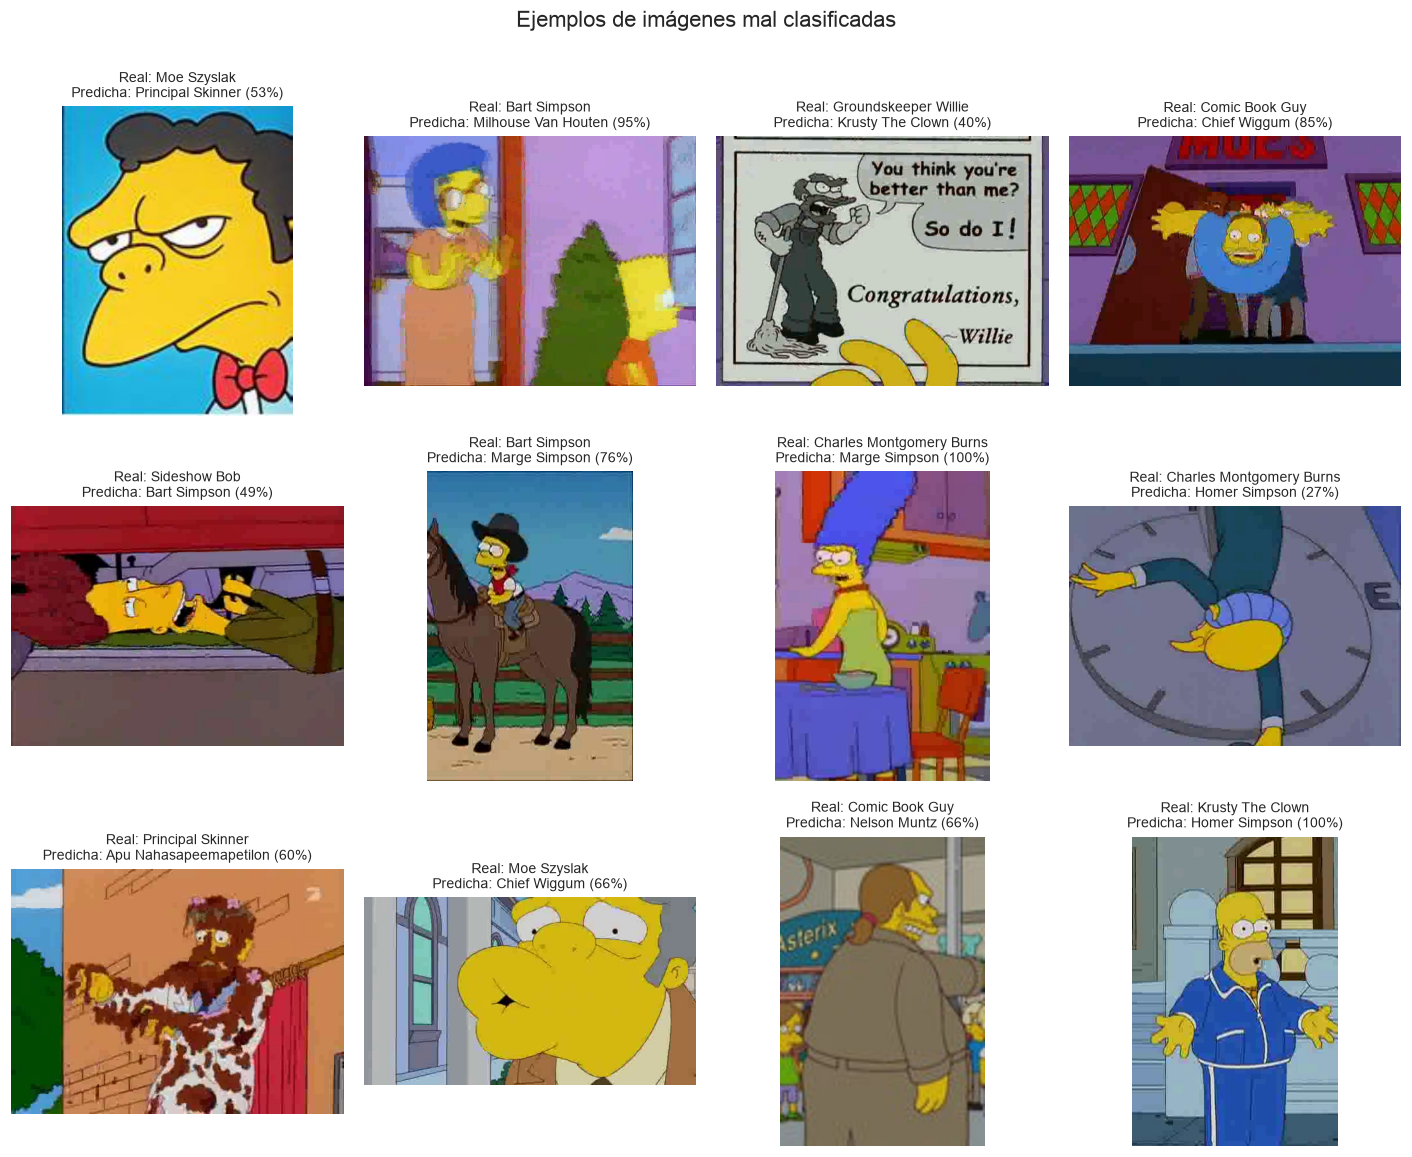

In [29]:
errores = np.flatnonzero(~acierto)
seleccion = np.random.default_rng(semilla).choice(errores, size=min(12, len(errores)), replace=False) if len(errores) else []
if len(seleccion):
    fig, axes = plt.subplots(3, 4, figsize=(13, 10.5))
    for ax in axes.flat:
        ax.axis("off")
    for ax, k in zip(axes.flat, seleccion):
        ax.imshow(Image.open(rutas_test[k]).convert("RGB"))
        ax.set_title(f"Real: {nombre_visible(NOMBRES[y_true[k]])}\nPredicha: {nombre_visible(NOMBRES[y_pred[k]])} ({confianza[k]:.0%})", fontsize=9)
    fig.suptitle("Ejemplos de imágenes mal clasificadas", y=1.0)
    fig.tight_layout()
    guardar_figura(fig, "11_errores")
    plt.show()

### 7.3 Capacidad de generalización

In [30]:
mejor_val = historial.loc[historial["epoch"] == mejor_epoca].iloc[0]
generalizacion = pd.DataFrame(
    {
        "accuracy top-1": {
            "Entrenamiento (muestra, sin aumentación)": mejor_val.get("train/accuracy_top1", np.nan),
            "Validación": mejor_val["metrics/accuracy_top1"],
            "Prueba": metricas_test["accuracy"],
        }
    }
)
display(generalizacion.round(4))

acc_train = mejor_val.get("train/accuracy_top1", np.nan)
brecha_val = acc_train - mejor_val["metrics/accuracy_top1"]
brecha_test = mejor_val["metrics/accuracy_top1"] - metricas_test["accuracy"]
print(f"Brecha entrenamiento − validación: {brecha_val:+.3f}")
print(f"Brecha validación − prueba:        {brecha_test:+.3f}")
if brecha_val > 0.05:
    print("→ Señal de sobreajuste: el modelo rinde notoriamente mejor en entrenamiento que en validación.")
elif acc_train < 0.80:
    print("→ Señal de subajuste: el modelo no alcanza un buen desempeño ni siquiera en entrenamiento.")
else:
    print("→ Sin señales fuertes de sobreajuste ni subajuste según la brecha de accuracy.")

,accuracy top-1
"Entrenamiento (muestra, sin aumentación)",1.0000
Validación,0.9898
Prueba,0.9921


Brecha entrenamiento − validación: +0.010
Brecha validación − prueba:        -0.002
→ Sin señales fuertes de sobreajuste ni subajuste según la brecha de accuracy.


> **Análisis crítico (completar tras ejecutar):** interpretar las curvas (¿en qué época se estabiliza la validación?, ¿crece la brecha?), las clases con menor F1 y su relación con el número de imágenes, los pares de personajes más confundidos (¿se parecen visualmente?) y la confianza de los errores. Indicar posibles sesgos, por ejemplo hacia los personajes con más imágenes.

## 8. Costo computacional

Datos para justificar el modelo final según la relación entre precisión, costo y factibilidad de despliegue. La latencia se mide con una imagen a la vez, que es el caso de la aplicación web.

In [31]:
def medir_latencia(modelo_torch, dispositivo, repeticiones):
    m = deepcopy(modelo_torch).float().to(dispositivo).eval()
    x = torch.rand(1, 3, IMGSZ, IMGSZ, device=dispositivo)
    with torch.no_grad():
        for _ in range(5):  # calentamiento
            m(x)
        if dispositivo != "cpu":
            torch.cuda.synchronize()
        inicio = time.perf_counter()
        for _ in range(repeticiones):
            m(x)
        if dispositivo != "cpu":
            torch.cuda.synchronize()
    return (time.perf_counter() - inicio) / repeticiones * 1000


capas, n_parametros, _, gflops = mejor_modelo.model.info(verbose=True, imgsz=IMGSZ)
costo = {
    "parametros_millones": round(n_parametros / 1e6, 2),
    "gflops": round(gflops, 2),
    "tamano_best_pt_mb": round((TEST_DIR / "weights" / "best.pt").stat().st_size / 1e6, 1),
    "latencia_cpu_ms": round(medir_latencia(mejor_modelo.model, "cpu", EVALUACION["repeticiones_latencia"]), 1),
    "latencia_gpu_ms": round(medir_latencia(mejor_modelo.model, "cuda", EVALUACION["repeticiones_latencia"]), 1)
    if torch.cuda.is_available() else None,
    "duracion_entrenamiento_min": configuracion.get("duracion_min"),
    "gpu": ENTORNO["gpu"],
}
guardar_json(costo, TEST_DIR / "costo_computacional.json")
pd.Series(costo, name=NOMBRE_TEST).to_frame()

YOLO11m-cls summary: 106 layers, 10,385,241 parameters, 0 gradients, 4.9 GFLOPs


,test1
parametros_millones,10.39
gflops,4.85
tamano_best_pt_mb,21.0
latencia_cpu_ms,23.5
latencia_gpu_ms,2.8
duracion_entrenamiento_min,20.1
gpu,NVIDIA GeForce RTX 4060 Laptop GPU


## 9. Registro de la prueba y exportación

- `resumen.md` en la carpeta de la prueba.
- Actualización de la tabla **Historial de pruebas** en `informe_yolo11.md`, a partir de todas las carpetas `testN`.
- Si `EXPORTAR_A_APP = True`, la prueba se exporta a `app/models/yolo11m-cls_testN/`: `model.pt` (copia de `best.pt`), `classes.json` y `modelo.json` (tipo de modelo, tamaño de entrada y métricas de prueba). Aparece en el selector de la aplicación web. Es lo mismo que ejecutar `python exportar_modelo.py testN` desde `DeepLearningModelos/`.

In [32]:
h = configuracion["hiperparametros"]
resumen = f'''# {NOMBRE_TEST} — YOLO11m-cls

- **Fecha:** {configuracion["inicio"]}  ·  **duración:** {configuracion.get("duracion_min")} min  ·  **GPU:** {ENTORNO["gpu"]}
- **Datos:** {configuracion["datos"]["clases"]} clases, división {configuracion["datos"]["imagenes"]}
- **Hiperparámetros:** imgsz {h["imgsz"]}, épocas {configuracion.get("epocas_ejecutadas")}/{h["epochs"]} (paciencia {h["patience"]}), lote {h["batch"]}, {h["optimizer"]} lr0 {h["lr0"]}, dropout {h["dropout"]}, cls_pw {h["cls_pw"]}
- **Mejor época (val top-1):** {mejor_epoca}

| Métrica (prueba) | Valor |
|---|---|
''' + "\n".join(f"| {k} | {v} |" for k, v in metricas_test.items()) + f'''

| Costo | Valor |
|---|---|
''' + "\n".join(f"| {k} | {v} |" for k, v in costo.items()) + "\n"
(TEST_DIR / "resumen.md").write_text(resumen, encoding="utf-8")


def actualizar_informe():
    filas = []
    pruebas = sorted(
        (p for p in RESULTADOS_DIR.glob("test*") if re.fullmatch(r"test\d+", p.name)),
        key=lambda p: int(p.name[4:]),
    )
    for d in pruebas:
        try:
            cfg = json.loads((d / "configuracion.json").read_text(encoding="utf-8"))
            met = json.loads((d / "metricas_test.json").read_text(encoding="utf-8"))
        except FileNotFoundError:
            continue
        hp = cfg["hiperparametros"]
        filas.append(
            f"| {d.name} | {cfg['inicio'][:10]} | {hp['imgsz']} | {cfg.get('epocas_ejecutadas', '?')}/{hp['epochs']} | "
            f"{hp['optimizer']} {hp['lr0']} | {hp['batch']} | {hp['dropout']} | {met['accuracy']:.4f} | "
            f"{met['f1_macro']:.4f} | {met['f1_ponderado']:.4f} | {cfg.get('duracion_min', '?')} |"
        )
    tabla = "\n".join(
        [
            "| Prueba | Fecha | imgsz | Épocas | Optimizador y lr0 | Lote | Dropout | Accuracy test | F1 macro | F1 ponderado | Duración (min) |",
            "|---|---|---|---|---|---|---|---|---|---|---|",
            *filas,
        ]
    )
    inicio, fin = "<!-- HISTORIAL:INICIO -->", "<!-- HISTORIAL:FIN -->"
    texto = INFORME_PATH.read_text(encoding="utf-8")
    if inicio in texto and fin in texto:
        antes, resto = texto.split(inicio, 1)
        _, despues = resto.split(fin, 1)
        INFORME_PATH.write_text(f"{antes}{inicio}\n{tabla}\n{fin}{despues}", encoding="utf-8")
        print(f"Historial actualizado en {INFORME_PATH.name} ({len(filas)} pruebas).")
    else:
        print(f"No se encontraron los marcadores del historial en {INFORME_PATH.name}.")


if INFORME_PATH.exists():
    actualizar_informe()
print(resumen)

Historial actualizado en informe_yolo11.md (1 pruebas).
# test1 — YOLO11m-cls

- **Fecha:** 2026-10-15T07:03:12  ·  **duración:** 20.1 min  ·  **GPU:** NVIDIA GeForce RTX 4060 Laptop GPU
- **Datos:** 25 clases, división {'train': 14128, 'val': 3028, 'test': 3028}
- **Hiperparámetros:** imgsz 224, épocas 47/50 (paciencia 10), lote -1, AdamW lr0 0.0005, dropout 0.2, cls_pw 0.0
- **Mejor época (val top-1):** 37

| Métrica (prueba) | Valor |
|---|---|
| imagenes_test | 3028 |
| accuracy | 0.9921 |
| accuracy_top5 | 0.9974 |
| precision_macro | 0.9933 |
| recall_macro | 0.9883 |
| f1_macro | 0.9907 |
| precision_ponderada | 0.9921 |
| recall_ponderado | 0.9921 |
| f1_ponderado | 0.9921 |

| Costo | Valor |
|---|---|
| parametros_millones | 10.39 |
| gflops | 4.85 |
| tamano_best_pt_mb | 21.0 |
| latencia_cpu_ms | 23.5 |
| latencia_gpu_ms | 2.8 |
| duracion_entrenamiento_min | 20.1 |
| gpu | NVIDIA GeForce RTX 4060 Laptop GPU |



In [33]:
if EXPORTAR_A_APP:
    if str(BASE_DIR) not in sys.path:
        sys.path.insert(0, str(BASE_DIR))
    from exportar_modelo import exportar_prueba_yolo

    destino = exportar_prueba_yolo(TEST_DIR, APP_DIR / "models")
    print(f"{NOMBRE_TEST} exportada a {destino.relative_to(BASE_DIR)}/ (aparece en el selector de la aplicación web).")
else:
    print(f"Exportación a la app desactivada (EXPORTAR_A_APP = False). Para exportar después: python exportar_modelo.py {NOMBRE_TEST}")

Exportación a la app desactivada (EXPORTAR_A_APP = False). Para exportar después: python exportar_modelo.py test1


## 10. Conclusión

> **Completar tras ejecutar las pruebas.** Estructura sugerida:
>
> 1. **Resultados:** accuracy, F1 macro y F1 ponderado en prueba de la mejor prueba (ver el historial en `informe_yolo11.md`).
> 2. **Generalización:** brechas entre entrenamiento, validación y prueba; ¿hubo sobreajuste o subajuste? ¿Qué mecanismo de regularización influyó más?
> 3. **Sesgos y errores:** clases con menor desempeño, relación con el número de imágenes y pares más confundidos.
> 4. **Costo y despliegue:** parámetros, GFLOPs, tamaño del peso y latencia en CPU/GPU. ¿Es viable para la aplicación web?
> 5. **Elección del modelo final:** justificación según precisión, costo computacional y factibilidad de despliegue, comparando con los modelos del resto del grupo.
> 6. **Trabajo futuro:** por ejemplo, ponderación por clase (`cls_pw`), mayor resolución, más épocas o más imágenes de los personajes minoritarios.